# 10 · 苍穹外卖：订单状态定时处理、来单提醒和客户催单

来源：本地 `讲义.rar / 讲义/day10/苍穹外卖-day10.md` 与 `PPT.rar / PPT/day10-订单状态定时处理、来单提醒和客户催单.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章先用 Spring Task 定时处理支付超时和长期派送订单，再用 WebSocket 建立管理端与服务端的双向长连接，最后实现支付成功后的来单提醒和用户催单。保留16段讲义代码、表格和配图，对照50页PPT；补充、勘误与验收清单独立标注，配图内嵌可离线阅读。

跟练依赖前面章节的订单状态、支付回调、管理端页面和用户登录。定时任务、WebSocket推送与订单状态更新是服务端行为；浏览器显示弹窗或语音只是收到消息后的表现层处理。

> **重点勘误。** 原定时任务按订单查询后逐条更新，存在重复执行和并发支付/履约竞争；WebSocket示例用非线程安全的HashMap管理会话，广播失败后也没有清理失效连接；催单接口只按id查订单，没有验证当前用户和订单是否允许催单；支付回调后的来单提醒必须只在“首次成功状态迁移”后发送，不能因重复通知重复播报。后面逐项说明修正位置。


## 本章路线、接口与状态（补充）

| 顺序 | 功能 | 核心规则 |
| --- | --- | --- |
| 1 | Spring Task | 启用调度，使用六字段 cron，明确时区与执行频率 |
| 2 | 订单定时处理 | 按状态和时间筛选，使用条件更新，避免覆盖并发支付或履约 |
| 3 | WebSocket | 连接建立、消息、关闭和异常都管理，广播不阻塞其他会话 |
| 4 | 来单提醒 | 支付状态首次从未支付变为已支付后，推送 type=1 |
| 5 | 客户催单 | 校验当前用户和可催单状态后，推送 type=2 |

### 关键状态

| 字段 | 值 | 含义 |
| --- | --- | --- |
| `orders.status` | 1 / 2 / 3 / 4 / 5 / 6 | 待付款、待接单、已接单、派送中、已完成、已取消 |
| `orders.pay_status` | 0 / 1 / 2 | 未支付、已支付、退款 |
| 消息 `type` | 1 / 2 | 来单提醒、客户催单 |

支付回调、定时取消、管理端接单和自动完成可能同时操作同一订单。数据库状态条件、幂等记录和明确的状态机比单纯依赖任务执行顺序更可靠。


## 课程内容

> **PPT对照：** 第1—4页。

- Spring Task
- 订单状态定时处理
- WebSocket
- 来单提醒
- 客户催单


功能实现：**订单状态定时处理**、**来单提醒**和**客户催单**

**订单状态定时处理：**

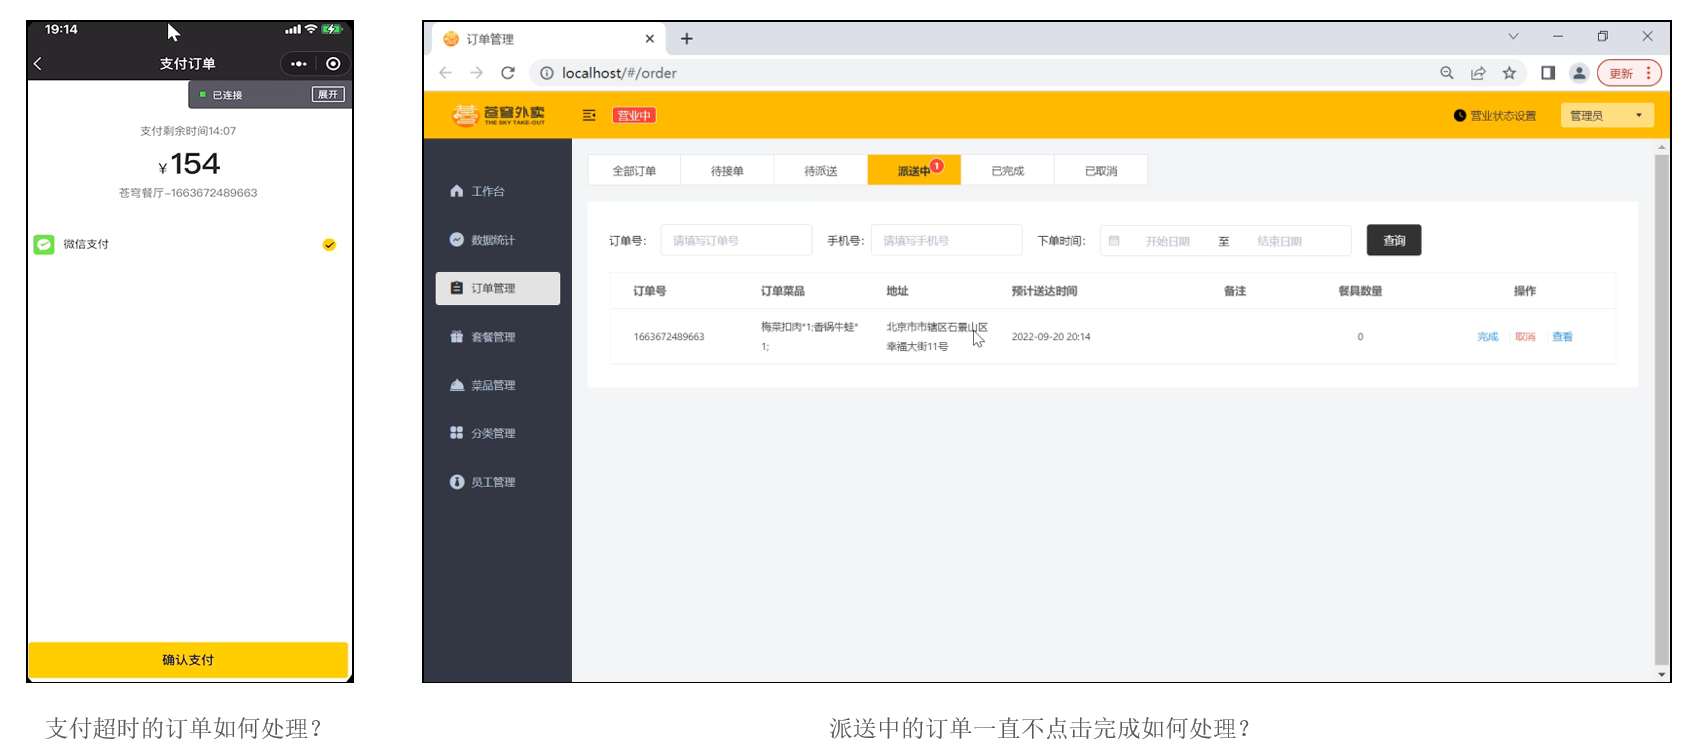 


**来单提醒：**

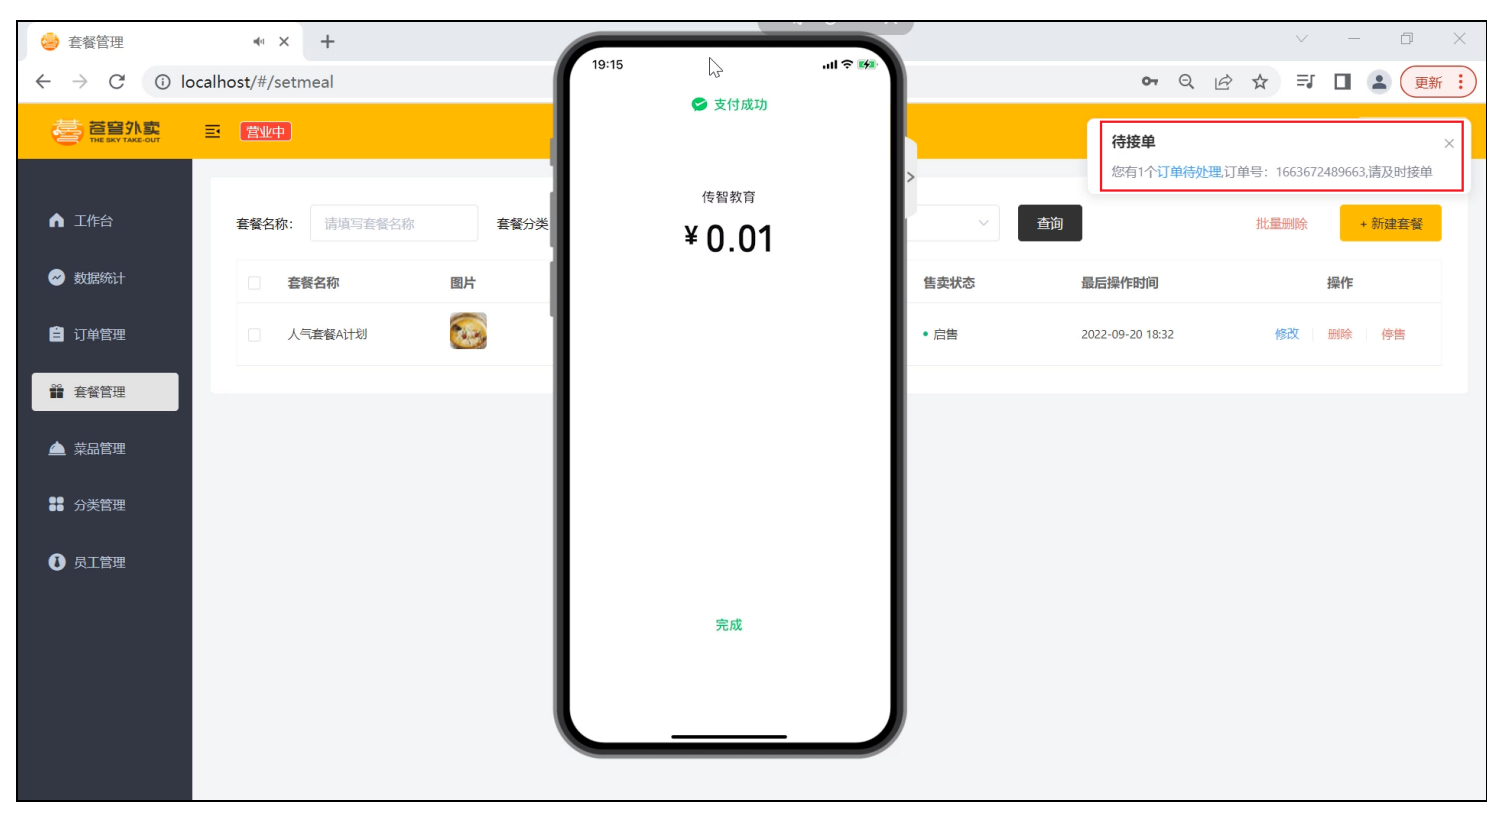 


**客户催单：**

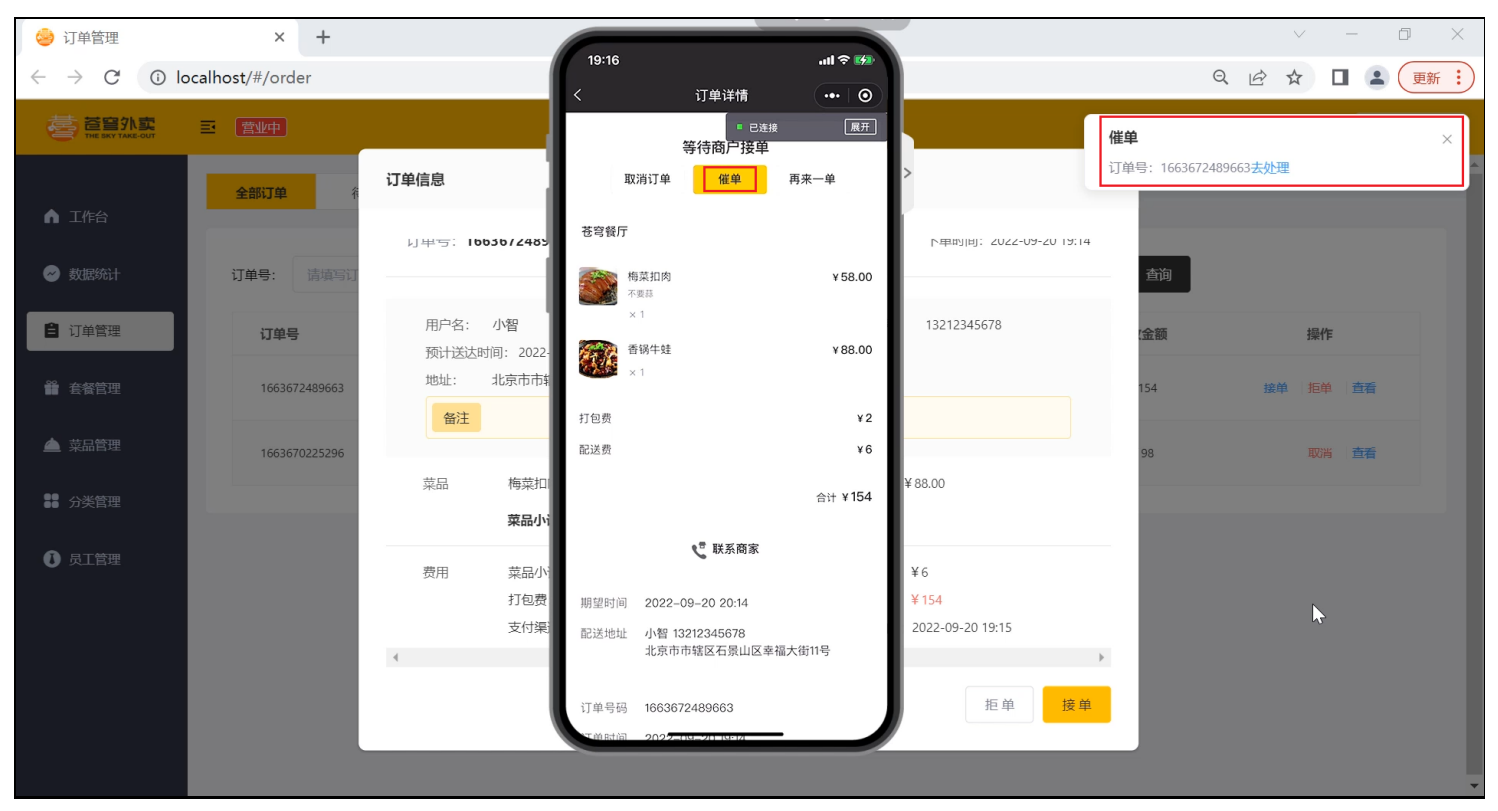


## 1. Spring Task

> **PPT对照：** 第5—12页。


### 1.1 介绍

> **PPT对照：** 第6—7页。

**Spring Task** 是Spring框架提供的任务调度工具，可以按照约定的时间自动执行某个代码逻辑。

**定位：**定时任务框架

**作用：**定时自动执行某段Java代码


 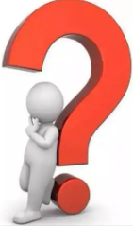 为什么要在Java程序中使用Spring Task？

**应用场景：**

1). 信用卡每月还款提醒

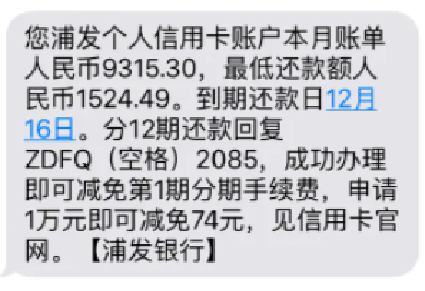 


2). 银行贷款每月还款提醒

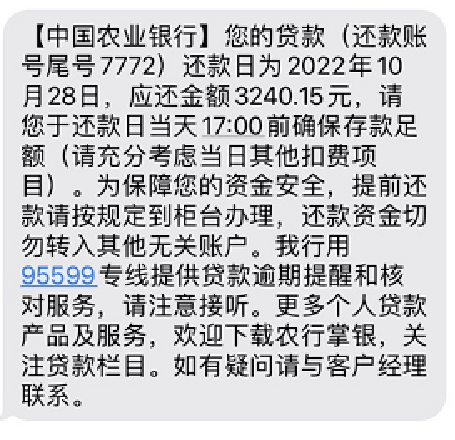 


3). 火车票售票系统处理未支付订单

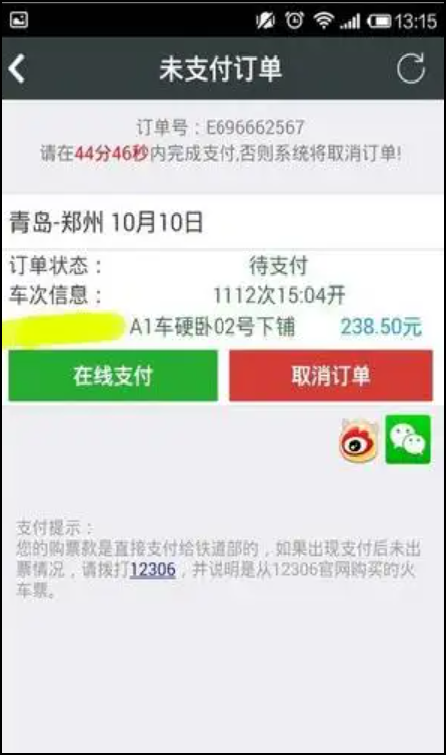 


4). 入职纪念日为用户发送通知

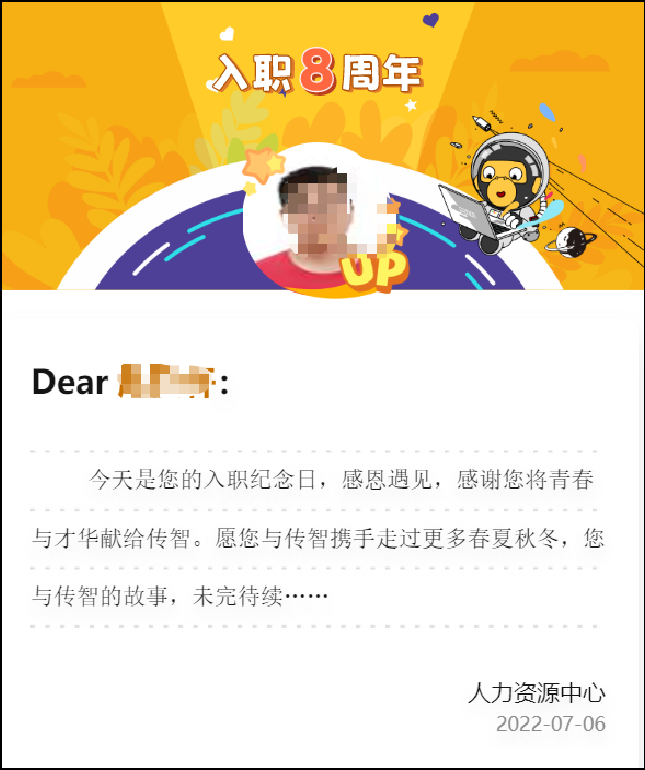 


**强调：**只要是需要定时处理的场景都可以使用Spring Task


### Spring Task 的边界与部署影响（补充）

`@Scheduled` 是进程内调度器。应用实例运行时才会执行，进程停止、容器重启或实例没有拿到任务时不会补执行历史任务。单实例课程项目可以这样入门；多实例部署时，同一个任务可能被每台实例同时触发，需要分布式锁、任务中心或把状态更新设计成可安全重复执行。

任务方法要保持短小，数据库查询和更新要有索引，避免一次扫描大量订单阻塞业务线程。长耗时任务应拆批、记录进度并设置超时，而不是在一个方法里无限处理。


### 1.2 cron表达式

> **PPT对照：** 第9—10页。

**cron表达式**其实就是一个字符串，通过cron表达式可以**定义任务触发的时间**

**构成规则：**分为6或7个域，由空格分隔开，每个域代表一个含义

每个域的含义分别为：秒、分钟、小时、日、月、周、年(可选)

**举例：**

2022年10月12日上午9点整 对应的cron表达式为：**0 0 9 12 10 ? 2022**

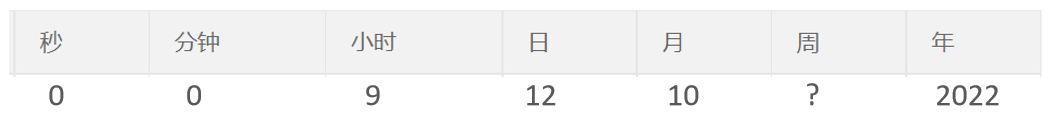 

**说明：**一般**日**和**周**的值不同时设置，其中一个设置，另一个用？表示。


**比如：**描述2月份的最后一天，最后一天具体是几号呢？可能是28号，也有可能是29号，所以就不能写具体数字。

为了描述这些信息，提供一些特殊的字符。这些具体的细节，我们就不用自己去手写，因为这个cron表达式，它其实有在线生成器。

cron表达式在线生成器：https://cron.qqe2.com/

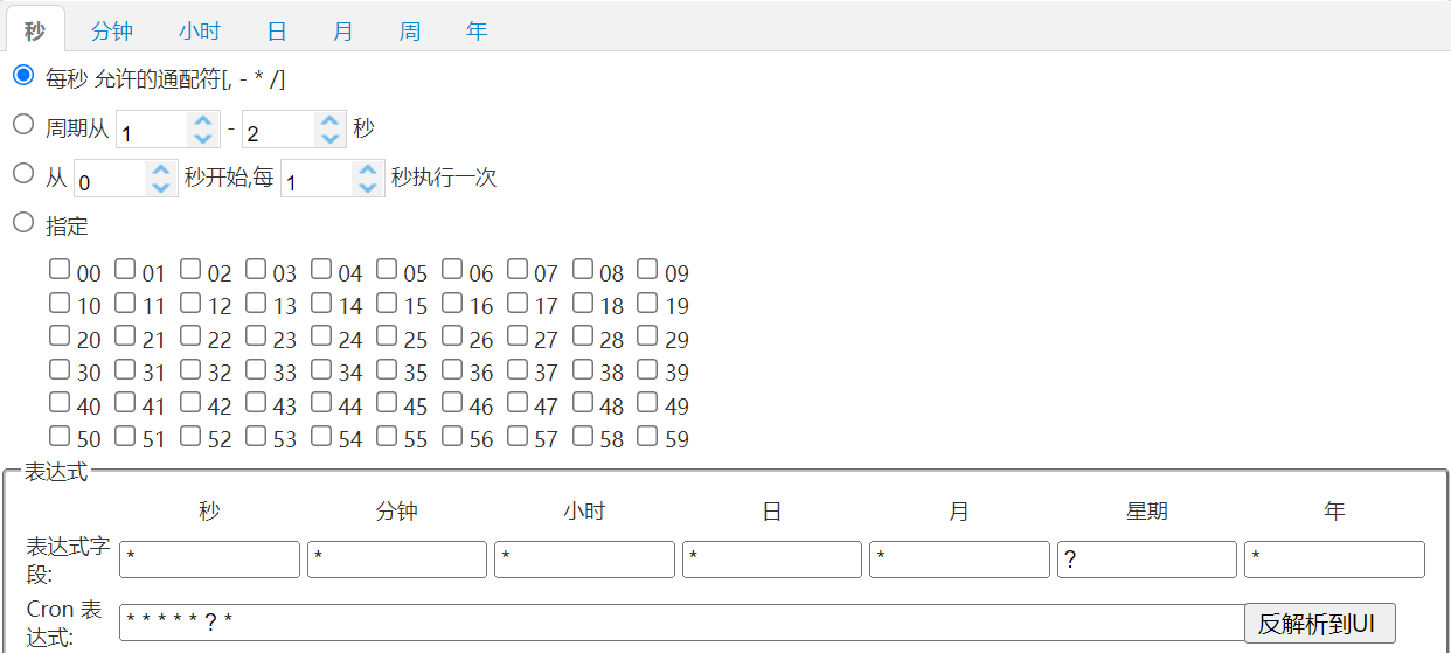 


可以直接在这个网站上面，只要根据自己的要求去生成corn表达式即可。所以一般就不用自己去编写这个表达式。

**通配符：**

\* 表示所有值； 

? 表示未说明的值，即不关心它为何值； 

\- 表示一个指定的范围； 

, 表示附加一个可能值； 

/ 符号前表示开始时间，符号后表示每次递增的值；

**cron表达式案例：**

*/5 * * * * ? 每隔5秒执行一次

0 */1 * * * ? 每隔1分钟执行一次

0 0 5-15 * * ? 每天5-15点整点触发

0 0/3 * * * ? 每三分钟触发一次

0 0-5 14 * * ? 在每天下午2点到下午2:05期间的每1分钟触发 

0 0/5 14 * * ? 在每天下午2点到下午2:55期间的每5分钟触发

0 0/5 14,18 * * ? 在每天下午2点到2:55期间和下午6点到6:55期间的每5分钟触发

0 0/30 9-17 * * ? 朝九晚五工作时间内每半小时

0 0 10,14,16 * * ? 每天上午10点，下午2点，4点


### cron 字段、时区与边界（补充）

Spring 默认使用六字段 cron：秒、分、时、日、月、周；年字段不是所有 Spring `@Scheduled` 版本都支持。`0 * * * * ?` 表示每分钟的第0秒触发，`0 0 1 * * ?` 表示每天凌晨1点触发。应用时区由 JVM 或 `@Scheduled(zone = "Asia/Shanghai")` 等配置决定，不能只看开发机时间。

常见表达式：

| 表达式 | 含义 |
| --- | --- |
| `0/5 * * * * ?` | 每5秒触发 |
| `0 * * * * ?` | 每分钟触发一次 |
| `0 0 1 * * ?` | 每天1点触发 |

任务临界点要按 `order_time < now - 15 minutes` 等明确规则计算。时钟回拨、夏令时和长时间执行都可能造成重复或跳过，应让业务更新具备幂等性。


### 1.3 入门案例

> **PPT对照：** 第12页。

#### 1.3.1 Spring Task使用步骤

1). 导入maven坐标 spring-context（已存在）

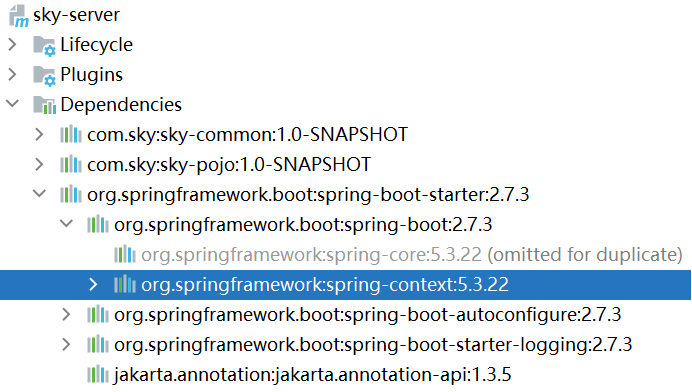 

2). 启动类添加注解 @EnableScheduling 开启任务调度

3). 自定义定时任务类


#### 1.3.2 代码开发

**编写定时任务类：**

进入sky-server模块中

```java
package com.sky.task;

import lombok.extern.slf4j.Slf4j;
import org.springframework.scheduling.annotation.Scheduled;
import org.springframework.stereotype.Component;

import java.util.Date;

/**
 * 自定义定时任务类
 */
@Component
@Slf4j
public class MyTask {

    /**
     * 定时任务 每隔5秒触发一次
     */
    @Scheduled(cron = "0/5 * * * * ?")
    public void executeTask(){
        log.info("定时任务开始执行：{}",new Date());
    }
}
```

**开启任务调度：**

启动类添加注解 @EnableScheduling

```java
package com.sky;

import lombok.extern.slf4j.Slf4j;
import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;
import org.springframework.cache.annotation.EnableCaching;
import org.springframework.scheduling.annotation.EnableScheduling;
import org.springframework.transaction.annotation.EnableTransactionManagement;

@SpringBootApplication
@EnableTransactionManagement //开启注解方式的事务管理
@Slf4j
@EnableCaching
@EnableScheduling
public class SkyApplication {
    public static void main(String[] args) {
        SpringApplication.run(SkyApplication.class, args);
        log.info("server started");
    }
}
```


#### 1.3.3 功能测试

启动服务，查看日志

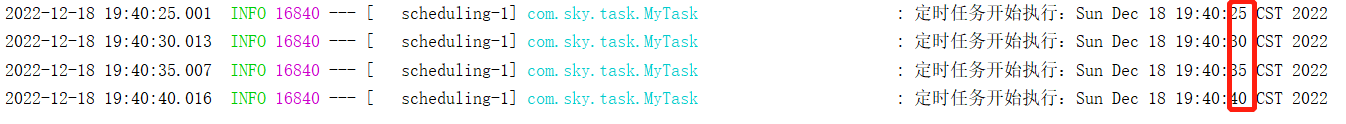 

每隔5秒执行一次。


### 调度启用与验证（补充）

`@EnableScheduling` 只负责打开调度扫描；任务类还必须是 Spring Bean（例如 `@Component`），方法不能依赖请求线程的用户上下文。测试时检查启动日志、任务实际时间和异常日志，不要仅凭应用启动成功判断任务已经执行。

任务中的异常不能静默吞掉。应记录任务名、扫描数量、成功数量和失败数量；单条订单失败时按批处理策略继续或让事务回滚，并保留可重试依据。


## 2.订单状态定时处理

> **PPT对照：** 第13—22页。


### 2.1 需求分析

> **PPT对照：** 第15页。

用户下单后可能存在的情况：

- 下单后未支付，订单一直处于**“待支付”**状态
- 用户收货后管理端未点击完成按钮，订单一直处于**“派送中”**状态

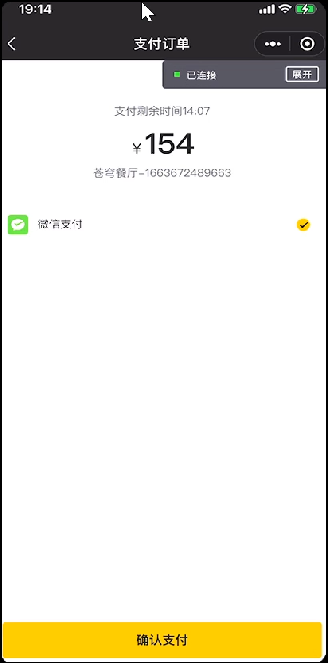                  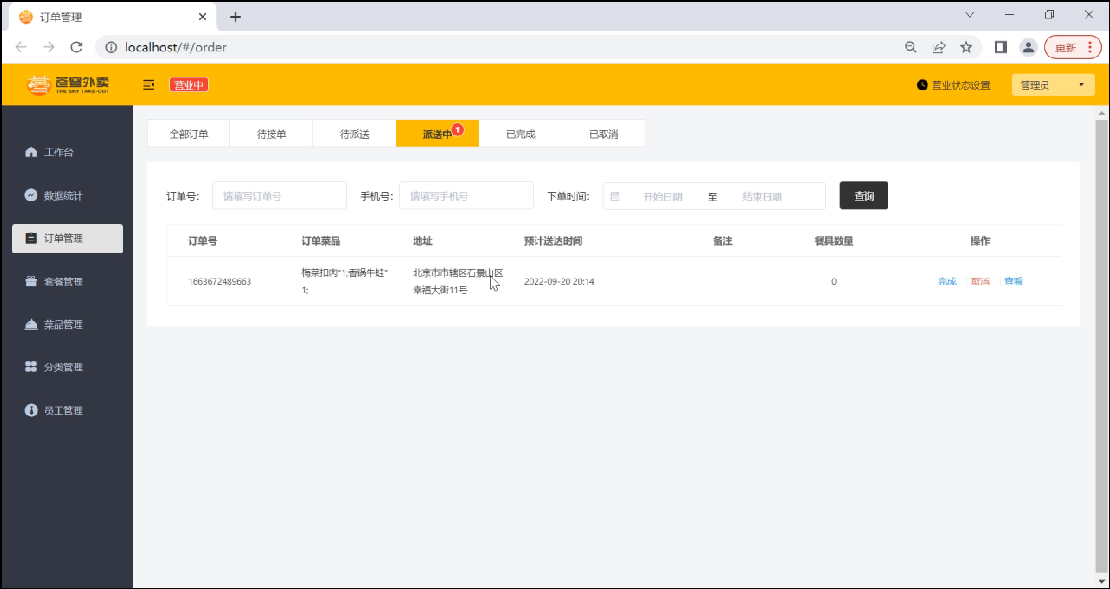

支付超时的订单如何处理？                                                       派送中的订单一直不点击完成如何处理？


对于上面两种情况需要通过**定时任务**来修改订单状态，具体逻辑为：

- 通过定时任务每分钟检查一次是否存在支付超时订单（下单后超过15分钟仍未支付则判定为支付超时订单），如果存在则修改订单状态为“已取消”
- 通过定时任务每天凌晨1点检查一次是否存在“派送中”的订单，如果存在则修改订单状态为“已完成”


### 自动取消与自动完成的业务边界（补充）

支付超时只应处理“待付款且未支付”的订单；收到可信支付成功通知后，订单必须退出这个集合。自动完成只应处理确实处于“派送中”的订单，并以预计送达、实际配送时间或业务约定的阈值为依据。讲义示例用下单时间减60分钟只是演示筛选，不能直接当作所有门店的配送规则。

取消、支付、接单和完成是状态迁移。每次迁移应检查前置状态，并保存取消原因、操作来源和时间。取消后才收到支付成功通知时，要进入对账、退款或人工处理流程，不能由定时任务和回调互相覆盖。


### 2.2 代码开发

> **PPT对照：** 第17—20页。

**1). 自定义定时任务类OrderTask（待完善）：**

```java
package com.sky.task;

/**
 * 自定义定时任务，实现订单状态定时处理
 */
@Component
@Slf4j
public class OrderTask {

    @Autowired
    private OrderMapper orderMapper;

    /**
     * 处理支付超时订单
     */
    @Scheduled(cron = "0 * * * * ?")
    public void processTimeoutOrder(){
        log.info("处理支付超时订单：{}", new Date());
    }

    /**
     * 处理“派送中”状态的订单
     */
    @Scheduled(cron = "0 0 1 * * ?")
    public void processDeliveryOrder(){
        log.info("处理派送中订单：{}", new Date());
    }

}
```


**2). 在OrderMapper接口中扩展方法:**

```java
	/**
     * 根据状态和下单时间查询订单
     * @param status
     * @param orderTime
     */
    @Select("select * from orders where status = #{status} and order_time < #{orderTime}")
    List<Orders> getByStatusAndOrdertimeLT(Integer status, LocalDateTime orderTime);
```


**3). 完善定时任务类的processTimeoutOrder方法：**

```java
	/**
     * 处理支付超时订单
     */
    @Scheduled(cron = "0 * * * * ?")
    public void processTimeoutOrder(){
        log.info("处理支付超时订单：{}", new Date());

        LocalDateTime time = LocalDateTime.now().plusMinutes(-15);

        // select * from orders where status = 1 and order_time < 当前时间-15分钟
        List<Orders> ordersList = orderMapper.getByStatusAndOrdertimeLT(Orders.PENDING_PAYMENT, time);
        if(ordersList != null && ordersList.size() > 0){
            ordersList.forEach(order -> {
                order.setStatus(Orders.CANCELLED);
                order.setCancelReason("支付超时，自动取消");
                order.setCancelTime(LocalDateTime.now());
                orderMapper.update(order);
            });
        }
    }
```


**4). 完善定时任务类的processDeliveryOrder方法：**

```java
	/**
     * 处理“派送中”状态的订单
     */
    @Scheduled(cron = "0 0 1 * * ?")
    public void processDeliveryOrder(){
        log.info("处理派送中订单：{}", new Date());
        // select * from orders where status = 4 and order_time < 当前时间-1小时
        LocalDateTime time = LocalDateTime.now().plusMinutes(-60);
        List<Orders> ordersList = orderMapper.getByStatusAndOrdertimeLT(Orders.DELIVERY_IN_PROGRESS, time);

        if(ordersList != null && ordersList.size() > 0){
            ordersList.forEach(order -> {
                order.setStatus(Orders.COMPLETED);
                orderMapper.update(order);
            });
        }
    }
```


### 订单定时任务的查询、更新与并发（补充与勘误）

原 `getByStatusAndOrdertimeLT` 只按状态和时间查询，随后逐条 `update`。这可以展示流程，但生产实现要同时考虑以下问题：

1. **条件更新。** 自动取消应类似 `update orders set status=6, cancel_reason=..., cancel_time=... where id=? and status=1 and pay_status=0`；自动完成应限定 `status=4`。影响行数为0时说明状态已经改变，不应覆盖最新结果。
2. **查询字段。** 支付超时用 `order_time`，配送完成最好使用明确的 `estimated_delivery_time` 或配送开始时间。字段和规则要与产品定义一致。
3. **批量与事务。** 大量订单应分页或分批处理；单批事务不要持有过多锁。每条更新成功后计数，失败记录订单号和原因。
4. **重复执行。** 任务可能重入或多实例同时执行，条件更新和唯一任务锁要组合使用。不要把 `@Scheduled` 当作分布式锁。

Mapper可以增加条件更新方法，示意如下：

```java
@Update("update orders set status = #{targetStatus}, " +
        "cancel_reason = #{cancelReason}, cancel_time = #{cancelTime} " +
        "where id = #{id} and status = 1 and pay_status = 0")
int cancelIfUnpaid(@Param("id") Long id,
                   @Param("targetStatus") Integer targetStatus,
                   @Param("cancelReason") String cancelReason,
                   @Param("cancelTime") LocalDateTime cancelTime);
```

实际项目应让 `targetStatus` 使用常量或固定SQL，不能让外部请求传入任意状态。原代码的 `ordersList.forEach` 适合学习流程，完善时要补充批量策略、索引（如status、order_time）和失败观测。


### 2.3 功能测试

> **PPT对照：** 第22页。

可以通过如下方式进行测试：

- 查看控制台sql
- 查看数据库中数据变化


**支付超时的订单测试：**

**1). 查看订单表**

有一条订单，状态为1。订单状态 1待付款 2待接单 3已接单 4派送中 5已完成 6已取消

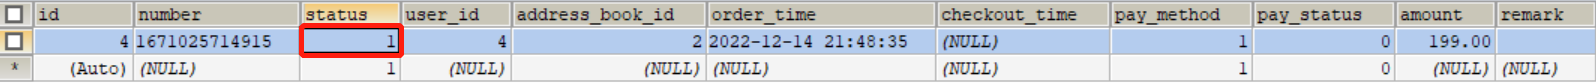 


**2). 开启定时任务**

启动服务，观察控制台日志。处理支付超时订单任务每隔1分钟执行一次。

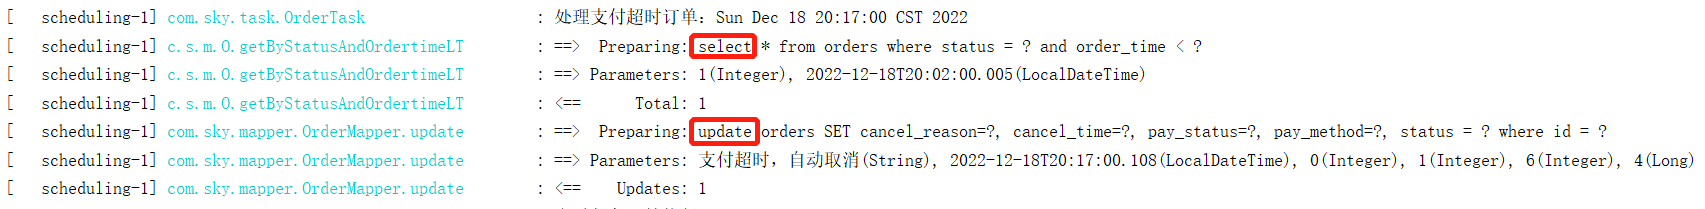 


**3). 再次查看订单表**

状态已更改为6，已取消。

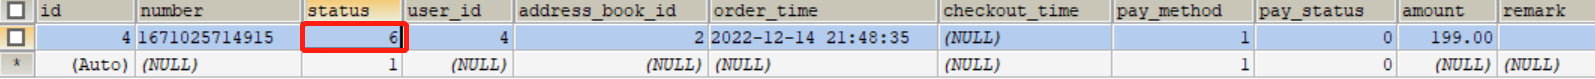 

证明定时任务已生效。

**处理“派送中”状态的订单任务**测试自已完成，测试步骤和上述一致。可适当修改cron表达式，改变任务执行频率，方便测试。


### 定时状态验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 待付款超过15分钟 | 只取消仍未支付的订单，写入原因和取消时间 |
| 待付款但刚收到支付成功通知 | 不被定时任务取消 |
| 派送中达到完成阈值 | 变为已完成并保留配送信息 |
| 已接单、已完成、已取消订单 | 不被错误任务改变 |
| 任务重复执行 | 不重复覆盖时间和原因，不产生副作用 |
| 两个实例同时执行 | 条件更新或锁保证最终状态一致 |
| 单条更新失败 | 按策略继续或回滚，并能定位失败订单 |

课程测试可以修改 cron 缩短等待时间，但测试后要恢复正式表达式。验证数据库变化时同时检查状态、支付状态、原因、时间和受影响行数。


## 3. WebSocket

> **PPT对照：** 第23—30页。


### 3.1 介绍

> **PPT对照：** 第25—27页。

WebSocket 是基于 TCP 的一种新的**网络协议**。它实现了浏览器与服务器全双工通信——浏览器和服务器只需要完成一次握手，两者之间就可以创建**持久性**的连接， 并进行**双向**数据传输。

**HTTP协议和WebSocket协议对比：**

- HTTP是**短连接**
- WebSocket是**长连接**
- HTTP通信是**单向**的，基于请求响应模式
- WebSocket支持**双向**通信
- HTTP和WebSocket底层都是TCP连接

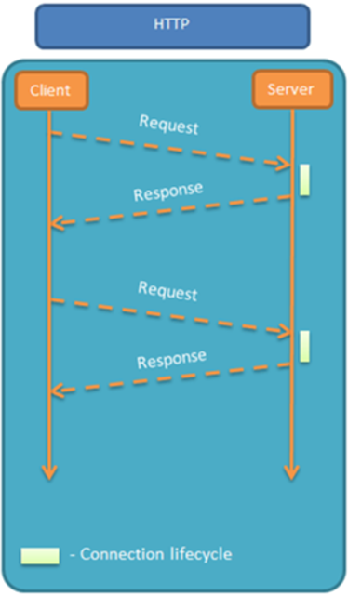           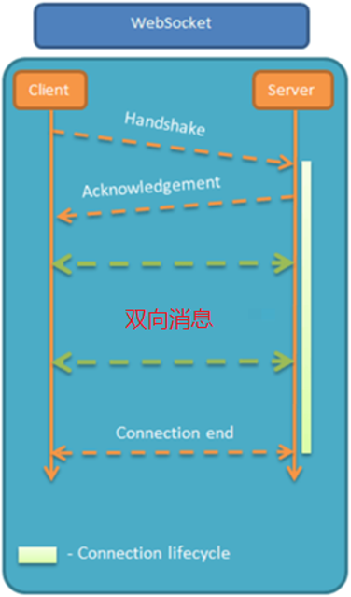 

**思考：**既然WebSocket支持双向通信，功能看似比HTTP强大，那么我们是不是可以基于WebSocket开发所有的业务功能？

**WebSocket缺点：**

服务器长期维护长连接需要一定的成本
各个浏览器支持程度不一
WebSocket 是长连接，受网络限制比较大，需要处理好重连

**结论：**WebSocket并不能完全取代HTTP，它只适合在特定的场景下使用


**WebSocket应用场景：**

1). 视频弹幕

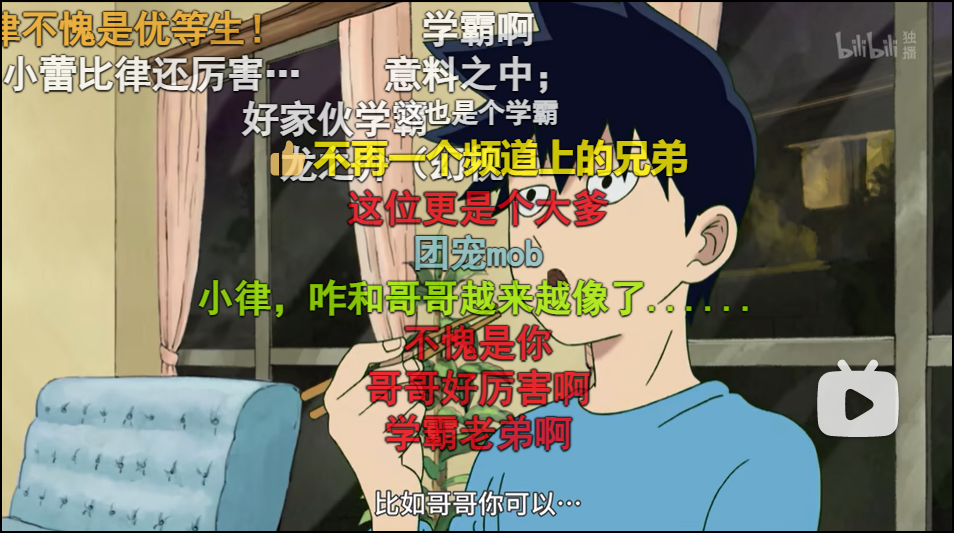v


2). 网页聊天

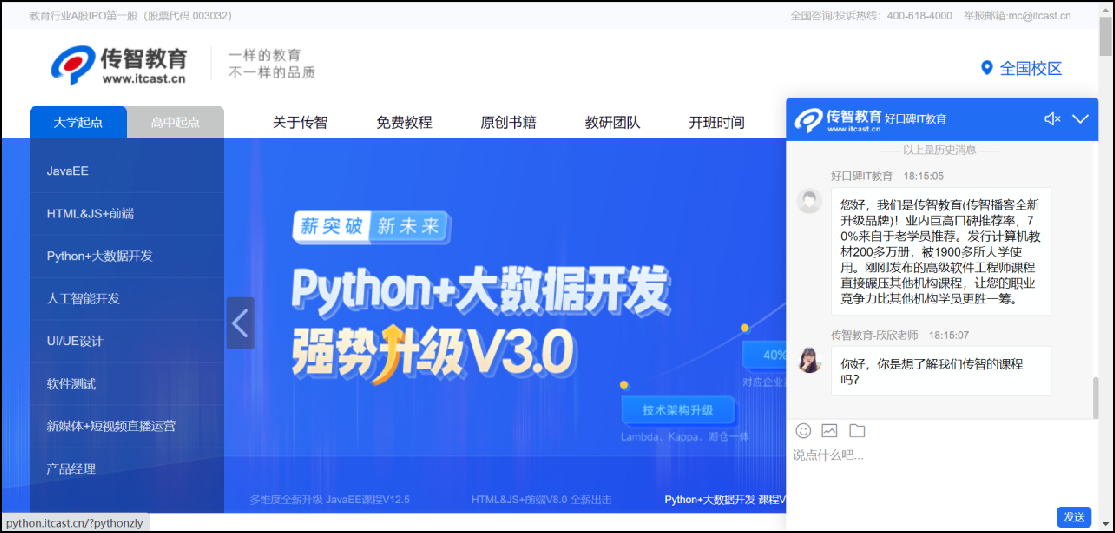 


3). 体育实况更新

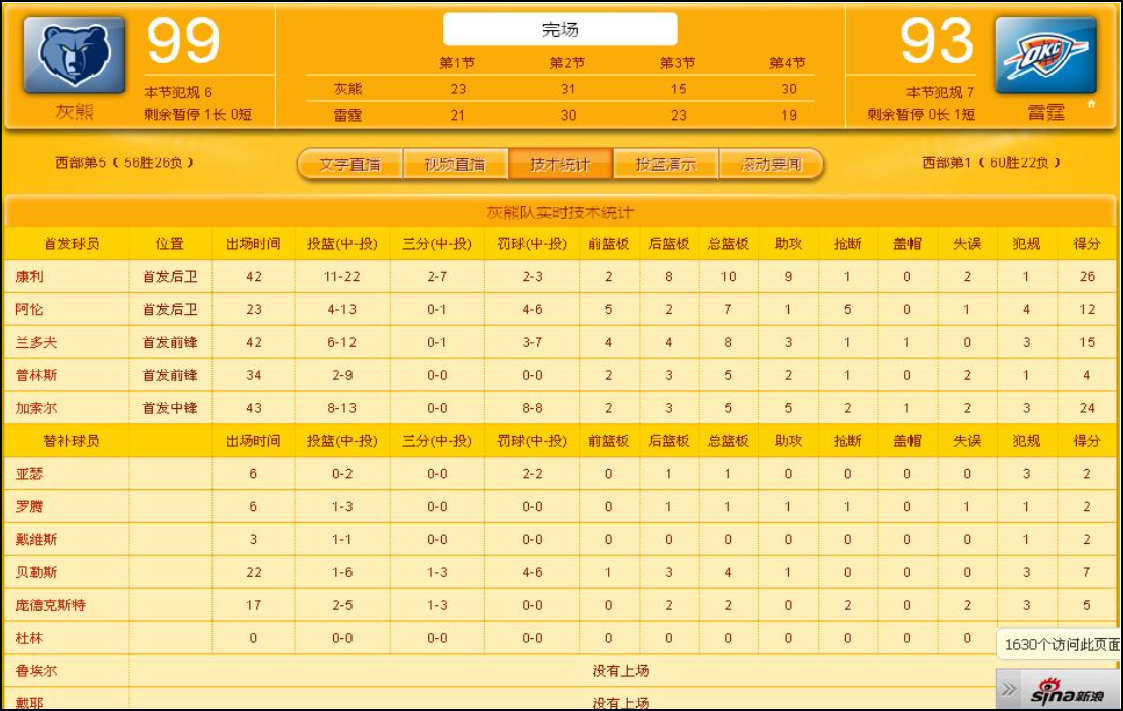 


4). 股票基金报价实时更新

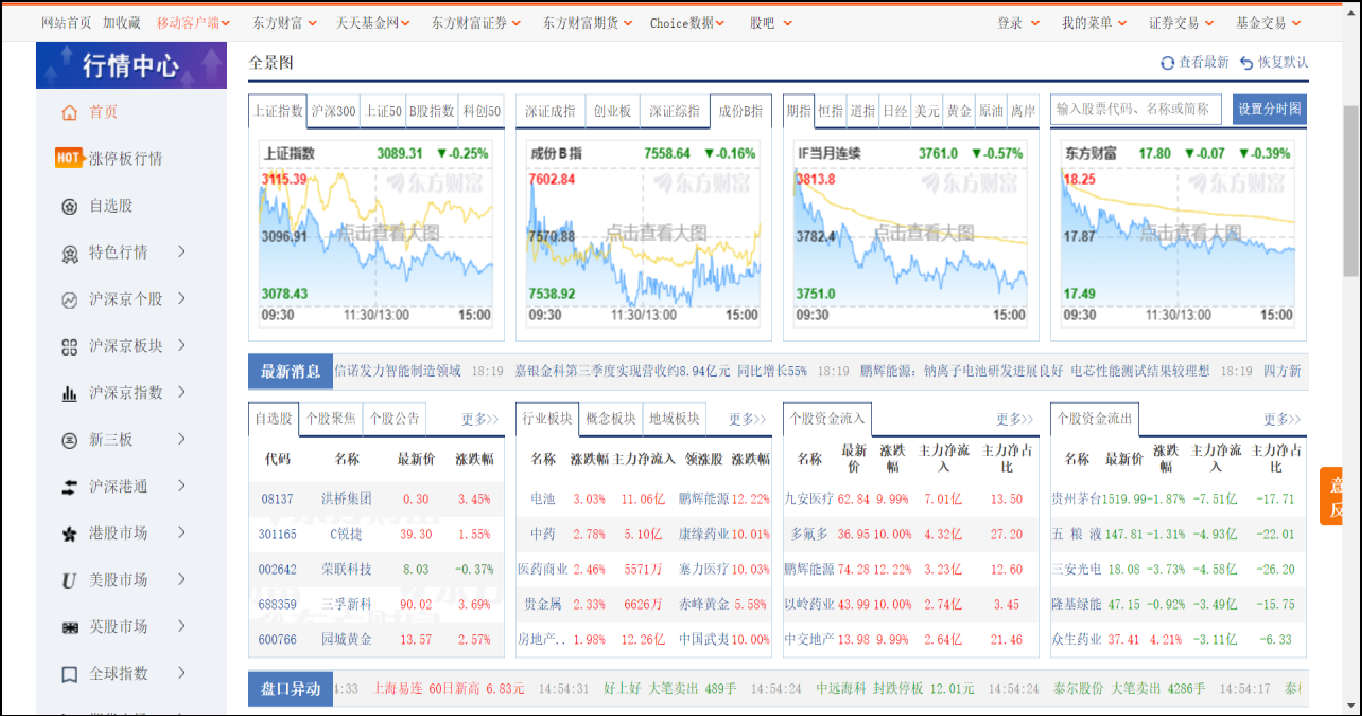


### WebSocket 连接模型与适用范围（补充）

WebSocket 连接经过HTTP握手后升级为长连接，之后双方都可以主动发送消息。它适合管理端实时提醒、聊天和实时看板；普通的查询、创建和修改仍使用HTTP接口。连接不是永久可靠的，浏览器休眠、网络切换、代理超时和服务重启都会导致断开。

客户端应处理 `open`、`message`、`error`、`close`，在允许的情况下采用退避重连，并避免重复注册事件。服务端推送消息要有版本或类型字段，客户端遇到未知类型应安全忽略。


### 3.2 入门案例

> **PPT对照：** 第29—30页。

#### 3.2.1 案例分析

**需求：**实现浏览器与服务器全双工通信。浏览器既可以向服务器发送消息，服务器也可主动向浏览器推送消息。

**效果展示：**

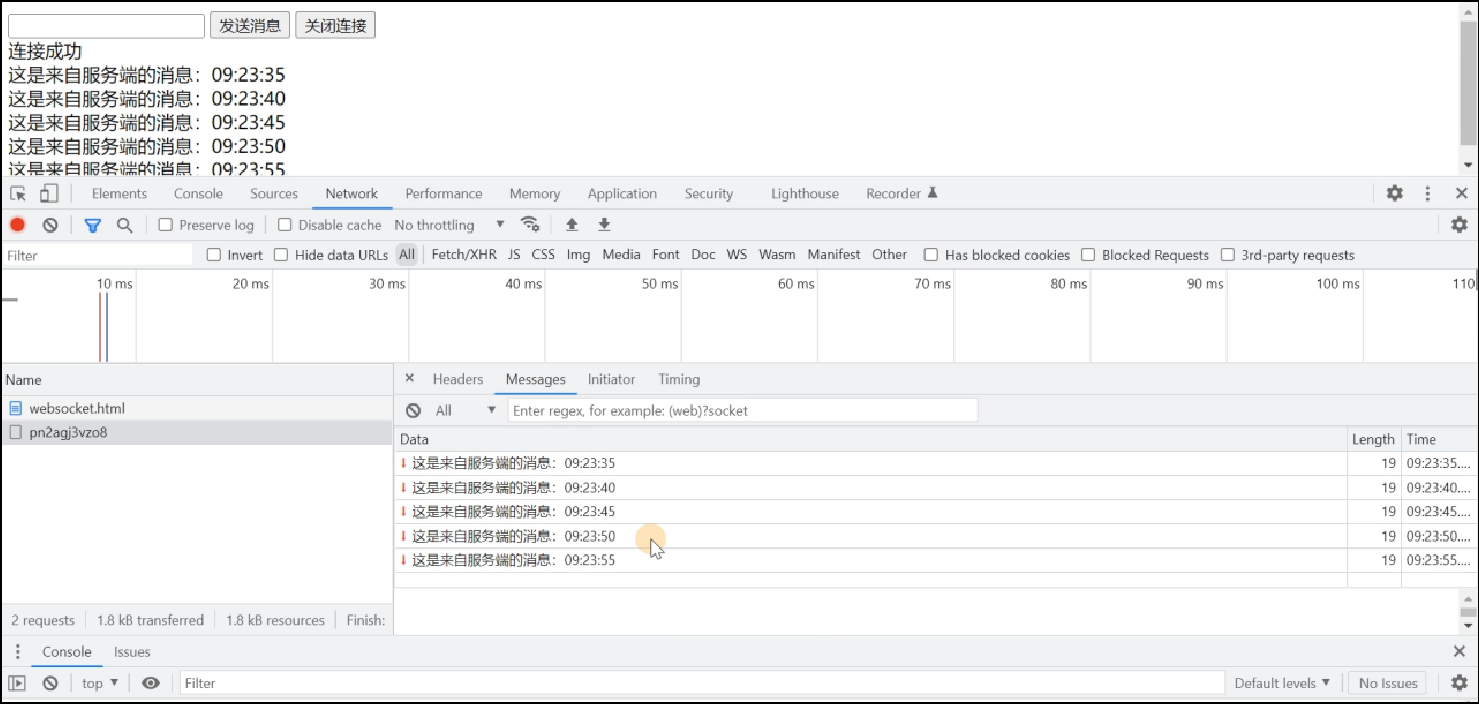 

**实现步骤：**

1). 直接使用websocket.html页面作为WebSocket客户端

2). 导入WebSocket的maven坐标

3). 导入WebSocket服务端组件WebSocketServer，用于和客户端通信

4). 导入配置类WebSocketConfiguration，注册WebSocket的服务端组件

5). 导入定时任务类WebSocketTask，定时向客户端推送数据


#### 3.2.2 代码开发

1). 定义websocket.html页面(资料中已提供)

```html
<!DOCTYPE HTML>
<html>
<head>
    <meta charset="UTF-8">
    <title>WebSocket Demo</title>
</head>
<body>
    <input id="text" type="text" />
    <button onclick="send()">发送消息</button>
    <button onclick="closeWebSocket()">关闭连接</button>
    <div id="message">
    </div>
</body>
<script type="text/javascript">
    var websocket = null;
    var clientId = Math.random().toString(36).substr(2);

    //判断当前浏览器是否支持WebSocket
    if('WebSocket' in window){
        //连接WebSocket节点
        websocket = new WebSocket("ws://localhost:8080/ws/"+clientId);
    }
    else{
        alert('Not support websocket')
    }

    //连接发生错误的回调方法
    websocket.onerror = function(){
        setMessageInnerHTML("error");
    };

    //连接成功建立的回调方法
    websocket.onopen = function(){
        setMessageInnerHTML("连接成功");
    }

    //接收到消息的回调方法
    websocket.onmessage = function(event){
        setMessageInnerHTML(event.data);
    }

    //连接关闭的回调方法
    websocket.onclose = function(){
        setMessageInnerHTML("close");
    }

    //监听窗口关闭事件，当窗口关闭时，主动去关闭websocket连接，防止连接还没断开就关闭窗口，server端会抛异常。
    window.onbeforeunload = function(){
        websocket.close();
    }

    //将消息显示在网页上
    function setMessageInnerHTML(innerHTML){
        document.getElementById('message').innerHTML += innerHTML + '<br/>';
    }

    //发送消息
    function send(){
        var message = document.getElementById('text').value;
        websocket.send(message);
    }
	
	//关闭连接
    function closeWebSocket() {
        websocket.close();
    }
</script>
</html>
```


2). 导入maven坐标

在sky-server模块pom.xml中已定义

```xml
<dependency>
	<groupId>org.springframework.boot</groupId>
	<artifactId>spring-boot-starter-websocket</artifactId>
</dependency>
```


3). 定义WebSocket服务端组件(资料中已提供)

直接导入到sky-server模块即可

```java
package com.sky.websocket;

import org.springframework.stereotype.Component;
import javax.websocket.OnClose;
import javax.websocket.OnMessage;
import javax.websocket.OnOpen;
import javax.websocket.Session;
import javax.websocket.server.PathParam;
import javax.websocket.server.ServerEndpoint;
import java.util.Collection;
import java.util.HashMap;
import java.util.Map;

/**
 * WebSocket服务
 */
@Component
@ServerEndpoint("/ws/{sid}")
public class WebSocketServer {

    //存放会话对象
    private static Map<String, Session> sessionMap = new HashMap();

    /**
     * 连接建立成功调用的方法
     */
    @OnOpen
    public void onOpen(Session session, @PathParam("sid") String sid) {
        System.out.println("客户端：" + sid + "建立连接");
        sessionMap.put(sid, session);
    }

    /**
     * 收到客户端消息后调用的方法
     *
     * @param message 客户端发送过来的消息
     */
    @OnMessage
    public void onMessage(String message, @PathParam("sid") String sid) {
        System.out.println("收到来自客户端：" + sid + "的信息:" + message);
    }

    /**
     * 连接关闭调用的方法
     *
     * @param sid
     */
    @OnClose
    public void onClose(@PathParam("sid") String sid) {
        System.out.println("连接断开:" + sid);
        sessionMap.remove(sid);
    }

    /**
     * 群发
     *
     * @param message
     */
    public void sendToAllClient(String message) {
        Collection<Session> sessions = sessionMap.values();
        for (Session session : sessions) {
            try {
                //服务器向客户端发送消息
                session.getBasicRemote().sendText(message);
            } catch (Exception e) {
                e.printStackTrace();
            }
        }
    }

}
```


4). 定义配置类，注册WebSocket的服务端组件(从资料中直接导入即可)

```java
package com.sky.config;

import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;
import org.springframework.web.socket.server.standard.ServerEndpointExporter;

/**
 * WebSocket配置类，用于注册WebSocket的Bean
 */
@Configuration
public class WebSocketConfiguration {

    @Bean
    public ServerEndpointExporter serverEndpointExporter() {
        return new ServerEndpointExporter();
    }

}
```


5). 定义定时任务类，定时向客户端推送数据(从资料中直接导入即可)

```java
package com.sky.task;

import com.sky.websocket.WebSocketServer;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.scheduling.annotation.Scheduled;
import org.springframework.stereotype.Component;
import java.time.LocalDateTime;
import java.time.format.DateTimeFormatter;

@Component
public class WebSocketTask {
    @Autowired
    private WebSocketServer webSocketServer;

    /**
     * 通过WebSocket每隔5秒向客户端发送消息
     */
    @Scheduled(cron = "0/5 * * * * ?")
    public void sendMessageToClient() {
        webSocketServer.sendToAllClient("这是来自服务端的消息：" + DateTimeFormatter.ofPattern("HH:mm:ss").format(LocalDateTime.now()));
    }
}
```


#### 3.2.3 功能测试

启动服务，打开websocket.html页面

**浏览器向服务器发送数据：**

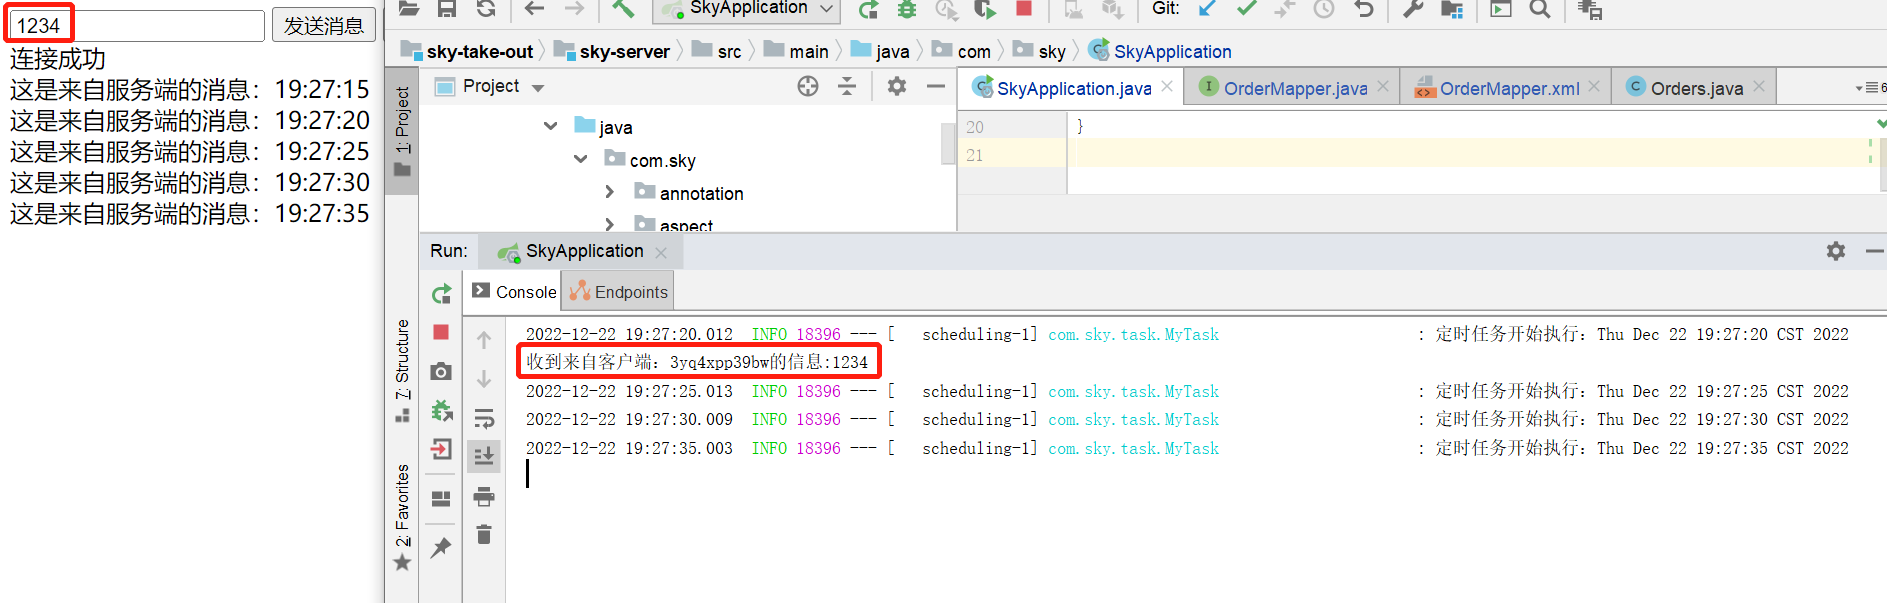 


**服务器向浏览器间隔5秒推送数据：**

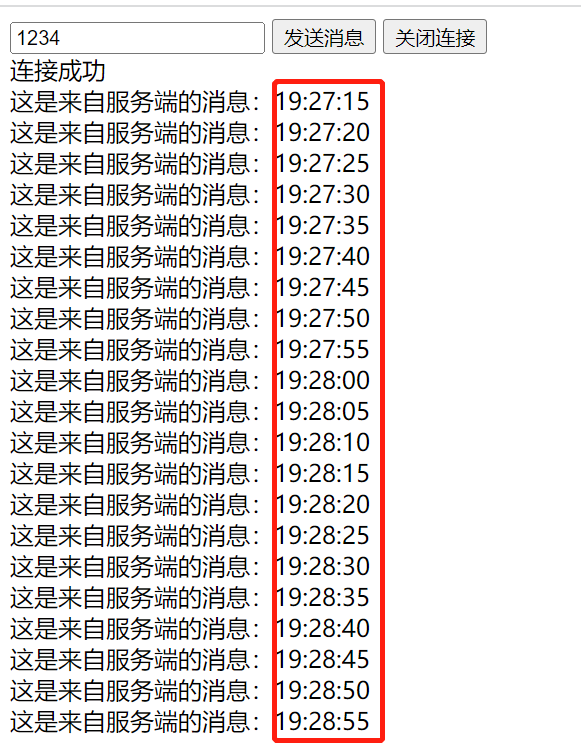


### WebSocket 示例的线程安全与资源管理（补充与勘误）

讲义使用静态 `HashMap<String, Session>` 保存连接。`@OnOpen`、`@OnClose` 和广播可能并发执行，生产代码至少应使用并发Map，例如 `ConcurrentHashMap`；广播时对会话集合做快照，避免遍历期间增删。发送失败要关闭并移除失效会话，不能让坏连接阻塞其他客户端。

`@ServerEndpoint` 的实例生命周期由WebSocket容器管理，依赖注入方式要与工程配置一致。不要在会话Map中保存敏感身份信息；sid应随机且不能作为越权依据。生产环境使用 `wss://`、校验Origin或登录票据，并设置连接空闲超时和消息大小上限。

示例的定时推送每5秒发送测试文本，启动后要关闭或改为业务事件推送，否则会产生无意义流量。HTML页面中的 `innerHTML` 直接插入服务端文本可能造成脚本注入，实际页面应使用 `textContent` 或严格转义。


## 4. 来单提醒

> **PPT对照：** 第31—38页。


### 4.1 需求分析和设计

> **PPT对照：** 第33—34页。

用户下单并且支付成功后，需要第一时间通知外卖商家。通知的形式有如下两种：

- 语音播报  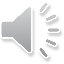
- 弹出提示框

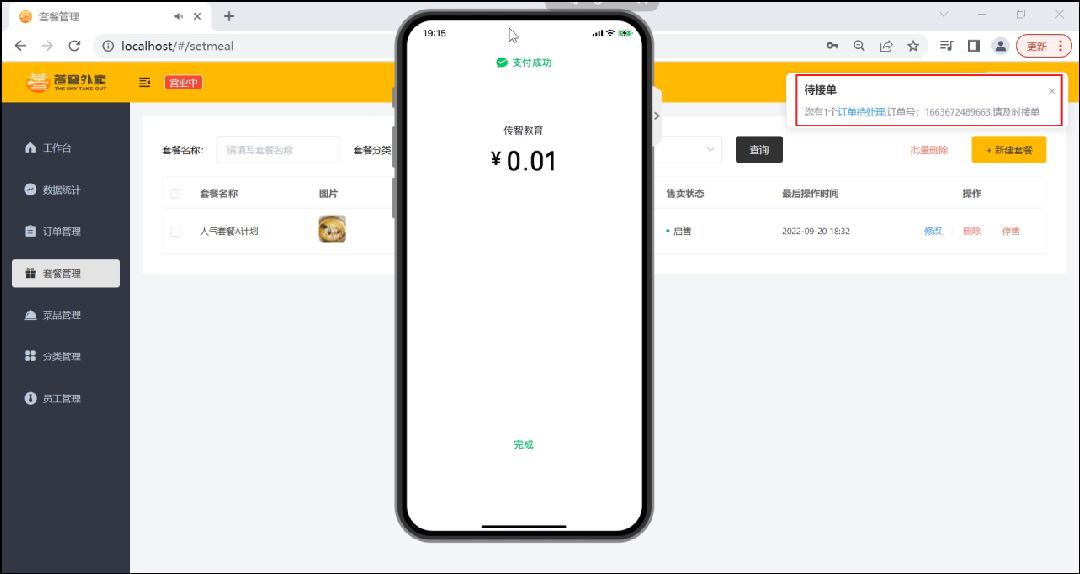 


**设计思路：**

- 通过WebSocket实现管理端页面和服务端保持长连接状态
- 当客户支付后，调用WebSocket的相关API实现服务端向客户端推送消息
- 客户端浏览器解析服务端推送的消息，判断是来单提醒还是客户催单，进行相应的消息提示和语音播报
- 约定服务端发送给客户端浏览器的数据格式为JSON，字段包括：type，orderId，content
  - type 为消息类型，1为来单提醒 2为客户催单
  - orderId 为订单id
  - content 为消息内容


### 来单提醒的事件一致性（补充）

来单提醒的触发点应是“订单支付状态首次确认成功”，而不是前端支付成功回调或每一次微信重复通知。建议先在本地事务中用条件更新完成未支付→已支付迁移，再在事务提交后发布提醒事件；只有影响行数为1时发送一次 `type=1` 消息。

消息示例：

```json
{"type":1,"orderId":123,"content":"订单号：202610090001"}
```

WebSocket推送是易失的，管理端断线时可能收不到。后台应通过订单列表/未处理订单查询补偿，不能把推送当作订单数据的唯一来源。语音播报和弹窗属于前端消费逻辑，服务端只约定稳定的数据结构。


### 4.2 代码开发

> **PPT对照：** 第36页。

**在OrderServiceImpl中注入WebSocketServer对象，修改paySuccess方法，加入如下代码：**

```java
	@Autowired
    private WebSocketServer webSocketServer;
	/**
     * 支付成功，修改订单状态
     *
     * @param outTradeNo
     */
    public void paySuccess(String outTradeNo) {
        // 当前登录用户id
        Long userId = BaseContext.getCurrentId();

        // 根据订单号查询当前用户的订单
        Orders ordersDB = orderMapper.getByNumberAndUserId(outTradeNo, userId);

        // 根据订单id更新订单的状态、支付方式、支付状态、结账时间
        Orders orders = Orders.builder()
                .id(ordersDB.getId())
                .status(Orders.TO_BE_CONFIRMED)
                .payStatus(Orders.PAID)
                .checkoutTime(LocalDateTime.now())
                .build();

        orderMapper.update(orders);
		//////////////////////////////////////////////
        Map map = new HashMap();
        map.put("type", 1);//消息类型，1表示来单提醒
        map.put("orderId", orders.getId());
        map.put("content", "订单号：" + outTradeNo);

        //通过WebSocket实现来单提醒，向客户端浏览器推送消息
        webSocketServer.sendToAllClient(JSON.toJSONString(map));
        ///////////////////////////////////////////////////
    }
```


### 支付成功后的推送边界（补充与勘误）

原 `paySuccess` 代码依赖 `BaseContext` 查询当前用户，这不适用于微信服务端回调；回调应先验签解密，再按商户订单号查订单。推送代码还要避免重复通知、避免把完整订单资料发给所有管理端，并处理没有在线客户端的情况。

推荐把通知发送放在本地事务提交之后，并把首次状态迁移和事件记录放在同一事务中：

```java
int changed = orderMapper.markPaidIfPending(orderId, paidAt);
if (changed == 1) {
    // after-commit handler / outbox：只发布一次来单提醒
    webSocketServer.sendToAllClient(JSON.toJSONString(message));
}
```

直接在事务内调用网络发送，事务回滚时客户端可能已经看到来单；直接在更新后无条件发送，又会因重复回调反复播报。可靠实现可使用事务事件或outbox表，失败后由重试任务补发。


### 4.3 功能测试

> **PPT对照：** 第38页。

可以通过如下方式进行测试：

- 查看浏览器调试工具数据交互过程
- 前后端联调

**1). 登录管理端后台**

登录成功后，浏览器与服务器建立长连接

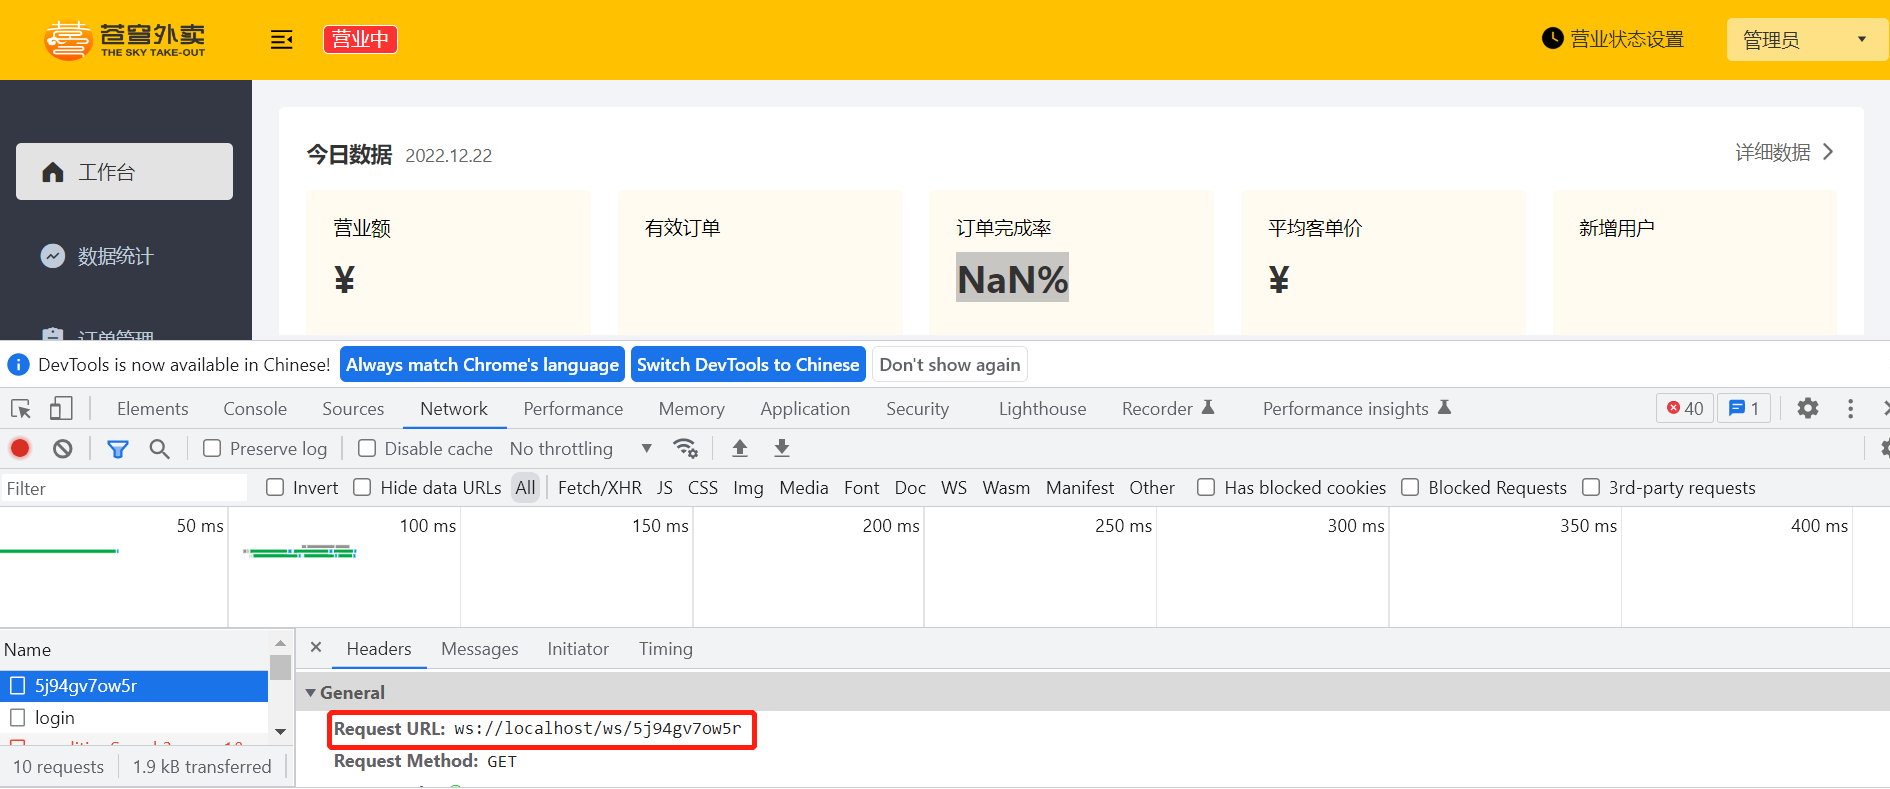 

查看控制台日志

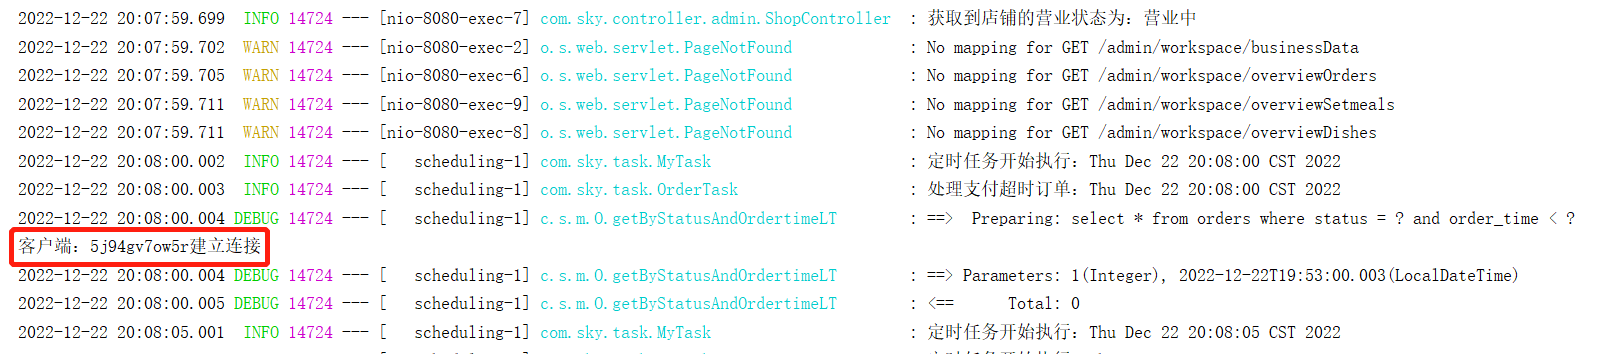 


**2). 小程序端下单支付**

修改回调地址，利用内网穿透获取域名

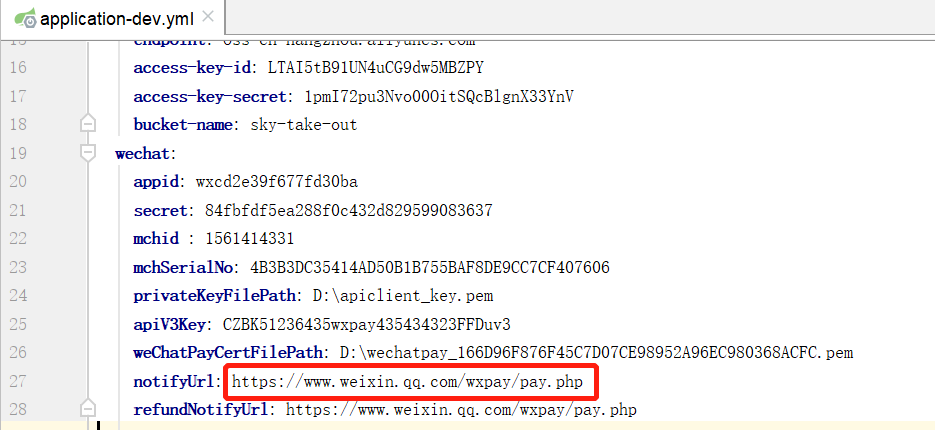 


下单支付

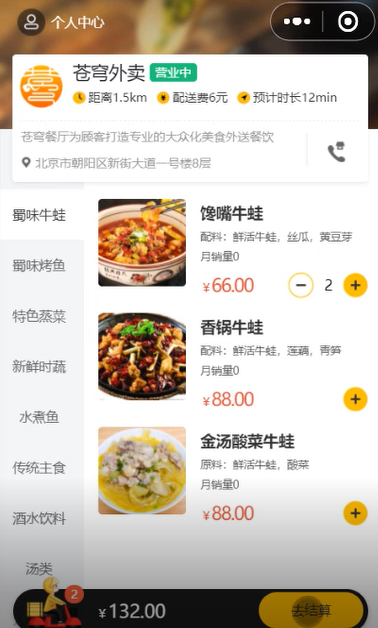 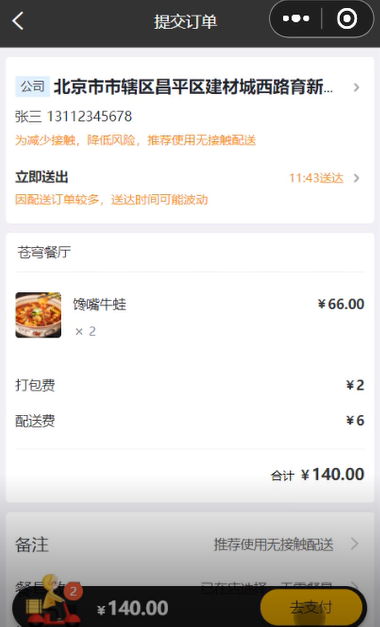 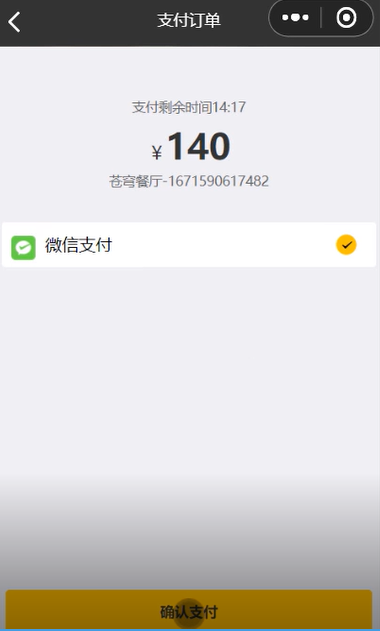 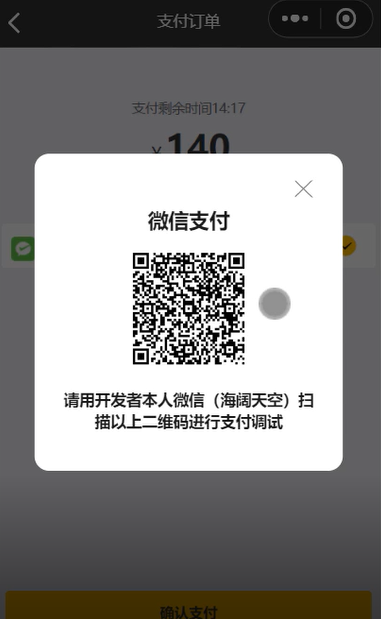


**3). 查看来单提醒**

支付成功后，后台收到来单提醒，并有语音播报

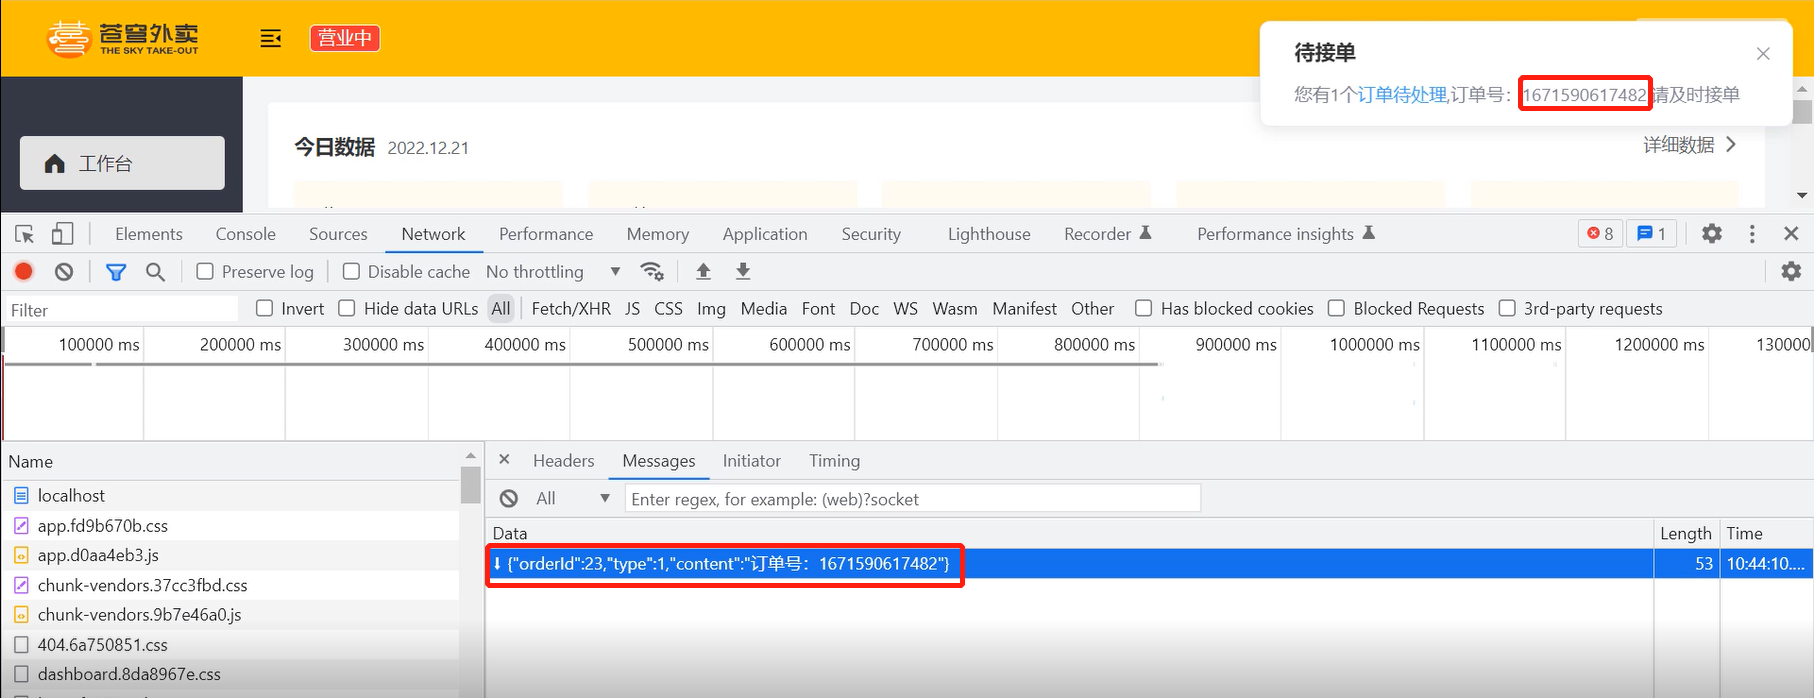


### 来单提醒验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 管理端在线，首次支付成功 | 收到 type=1、订单id和订单号 |
| 管理端断线后支付成功 | 订单仍保存，重连后可通过列表补看 |
| 重复支付通知 | 只产生一次来单提醒 |
| 非成功交易或验签失败 | 不更新订单，不推送提醒 |
| 多个管理端在线 | 广播失败的连接不影响其他连接 |
| 恶意构造消息 | 服务端不把客户端消息当作已支付事件 |

测试支付回调时使用隔离环境和模拟适配器；前端弹窗出现只能证明消息到达，仍需核对数据库状态和消息内容。


### 4.4 代码提交

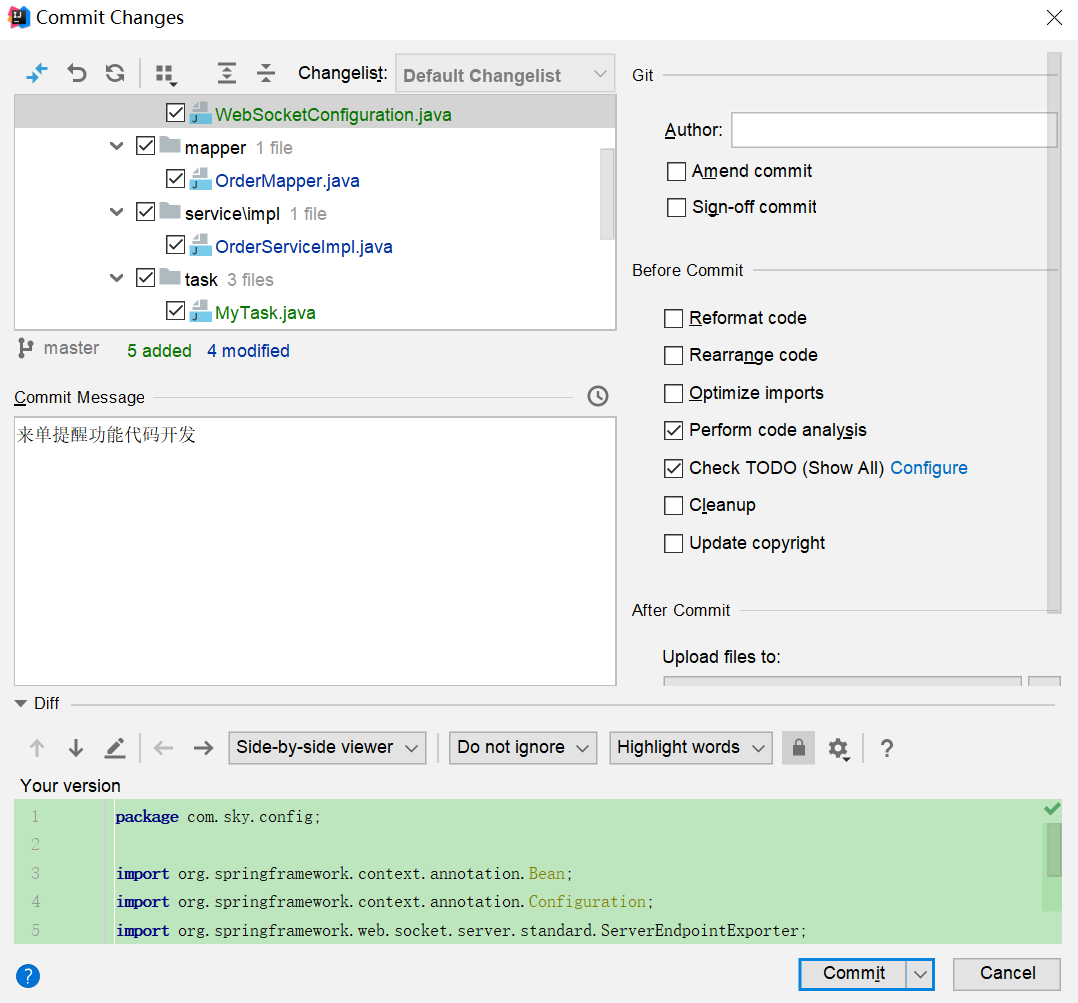 

后续步骤和其它功能代码提交一致，不再赘述。


### 提交前检查（补充）

提交定时任务和来单提醒前，检查 cron 是否使用目标时区、订单状态迁移是否有前置条件、推送是否在事务提交后发生、重复通知是否只产生一次消息，并移除测试用的每5秒广播任务。


## 5. 客户催单

> **PPT对照：** 第39—49页。


### 5.1 需求分析和设计

> **PPT对照：** 第41—43页。

用户在小程序中点击催单按钮后，需要第一时间通知外卖商家。通知的形式有如下两种：

- 语音播报 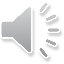
- 弹出提示框

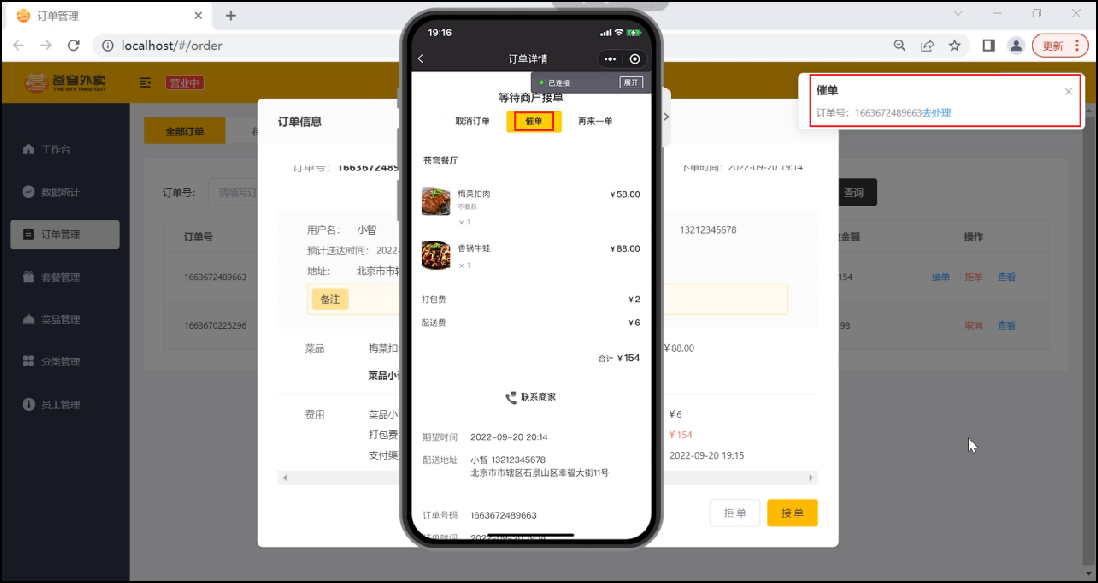 


**设计思路：**

- 通过WebSocket实现管理端页面和服务端保持长连接状态
- 当用户点击催单按钮后，调用WebSocket的相关API实现服务端向客户端推送消息
- 客户端浏览器解析服务端推送的消息，判断是来单提醒还是客户催单，进行相应的消息提示和语音播报
  约定服务端发送给客户端浏览器的数据格式为JSON，字段包括：type，orderId，content
  - type 为消息类型，1为来单提醒 2为客户催单
  - orderId 为订单id
  - content 为消息内容


当用户点击催单按钮时，向服务端发送请求。

**接口设计(催单)：**

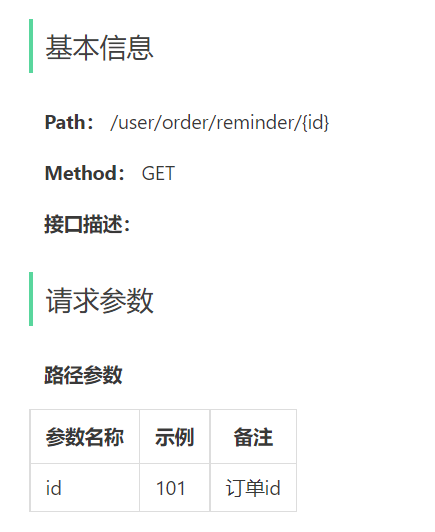 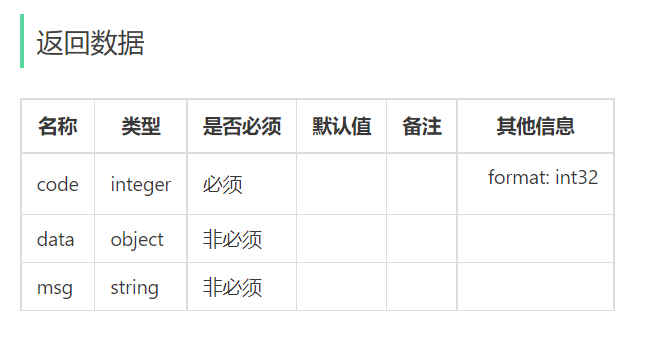


### 催单接口的授权和频率限制（补充）

用户催单必须校验订单属于当前用户，并限制在允许催单的状态，例如已支付、待接单或派送中。待付款、已取消、已完成或不存在的订单不应广播催单。原示例只按id查询，会让任意登录用户猜测订单id后向商家发送消息。

同一订单应有冷却时间或频率限制，避免重复点击造成消息洪泛。服务端消息只携带订单id和必要摘要，管理端收到后再调用受保护的订单详情接口读取完整信息。


### 5.2 代码开发

> **PPT对照：** 第45—47页。

#### 5.2.1 Controller层

**根据用户催单的接口定义，在user/OrderController中创建催单方法：**

```java
	/**
     * 用户催单
     *
     * @param id
     * @return
     */
    @GetMapping("/reminder/{id}")
    @ApiOperation("用户催单")
    public Result reminder(@PathVariable("id") Long id) {
        orderService.reminder(id);
        return Result.success();
    }
```


#### 5.2.2 Service层接口

**在OrderService接口中声明reminder方法：**

```java
	/**
     * 用户催单
     * @param id
     */
    void reminder(Long id);
```


#### 5.2.3 Service层实现类

**在OrderServiceImpl中实现reminder方法：**

```java
	/**
     * 用户催单
     *
     * @param id
     */
    public void reminder(Long id) {
        // 查询订单是否存在
        Orders orders = orderMapper.getById(id);
        if (orders == null) {
            throw new OrderBusinessException(MessageConstant.ORDER_NOT_FOUND);
        }

        //基于WebSocket实现催单
        Map map = new HashMap();
        map.put("type", 2);//2代表用户催单
        map.put("orderId", id);
        map.put("content", "订单号：" + orders.getNumber());
        webSocketServer.sendToAllClient(JSON.toJSONString(map));
    }
```


5.2.4 Mapper层

**在OrderMapper中添加getById：**

```java
	/**
     * 根据id查询订单
     * @param id
     */
    @Select("select * from orders where id=#{id}")
    Orders getById(Long id);
```


### 催单实现的归属、状态与幂等（补充与勘误）

Controller层的 `GET /reminder/{id}` 可以保留课程接口，但服务层应改为按“订单id + 当前用户id”查询，并验证状态和最近催单时间：

```java
Long userId = BaseContext.getCurrentId();
if (userId == null || id == null) {
    throw new OrderBusinessException("登录身份或订单参数不合法");
}
Orders order = orderMapper.getByIdAndUserId(id, userId);
if (order == null || !Set.of(Orders.TO_BE_CONFIRMED,
        Orders.CONFIRMED, Orders.DELIVERY_IN_PROGRESS).contains(order.getStatus())) {
    throw new OrderBusinessException("当前订单不能催单");
}
```

`Set.of` 只适合 Java 9+；按项目版本改为已有集合或多个常量判断。最好在数据库条件更新中记录 `last_reminder_time`，用影响行数实现冷却期幂等。Mapper示意：

```java
@Select("select * from orders where id = #{id} and user_id = #{userId}")
Orders getByIdAndUserId(@Param("id") Long id, @Param("userId") Long userId);
```

原 `getById(Long id)` 和 `Map` 原始类型适合课堂展示，实际代码要补 `@Param`、泛型、日志和异常处理。广播失败不应让催单接口误报数据库操作失败；可以记录消息投递结果并由管理端订单列表兜底。


### 5.3 功能测试

> **PPT对照：** 第49页。

可以通过如下方式进行测试：

- 查看浏览器调试工具数据交互过程
- 前后端联调

**1). 登录管理端后台**

登录成功后，浏览器与服务器建立长连接

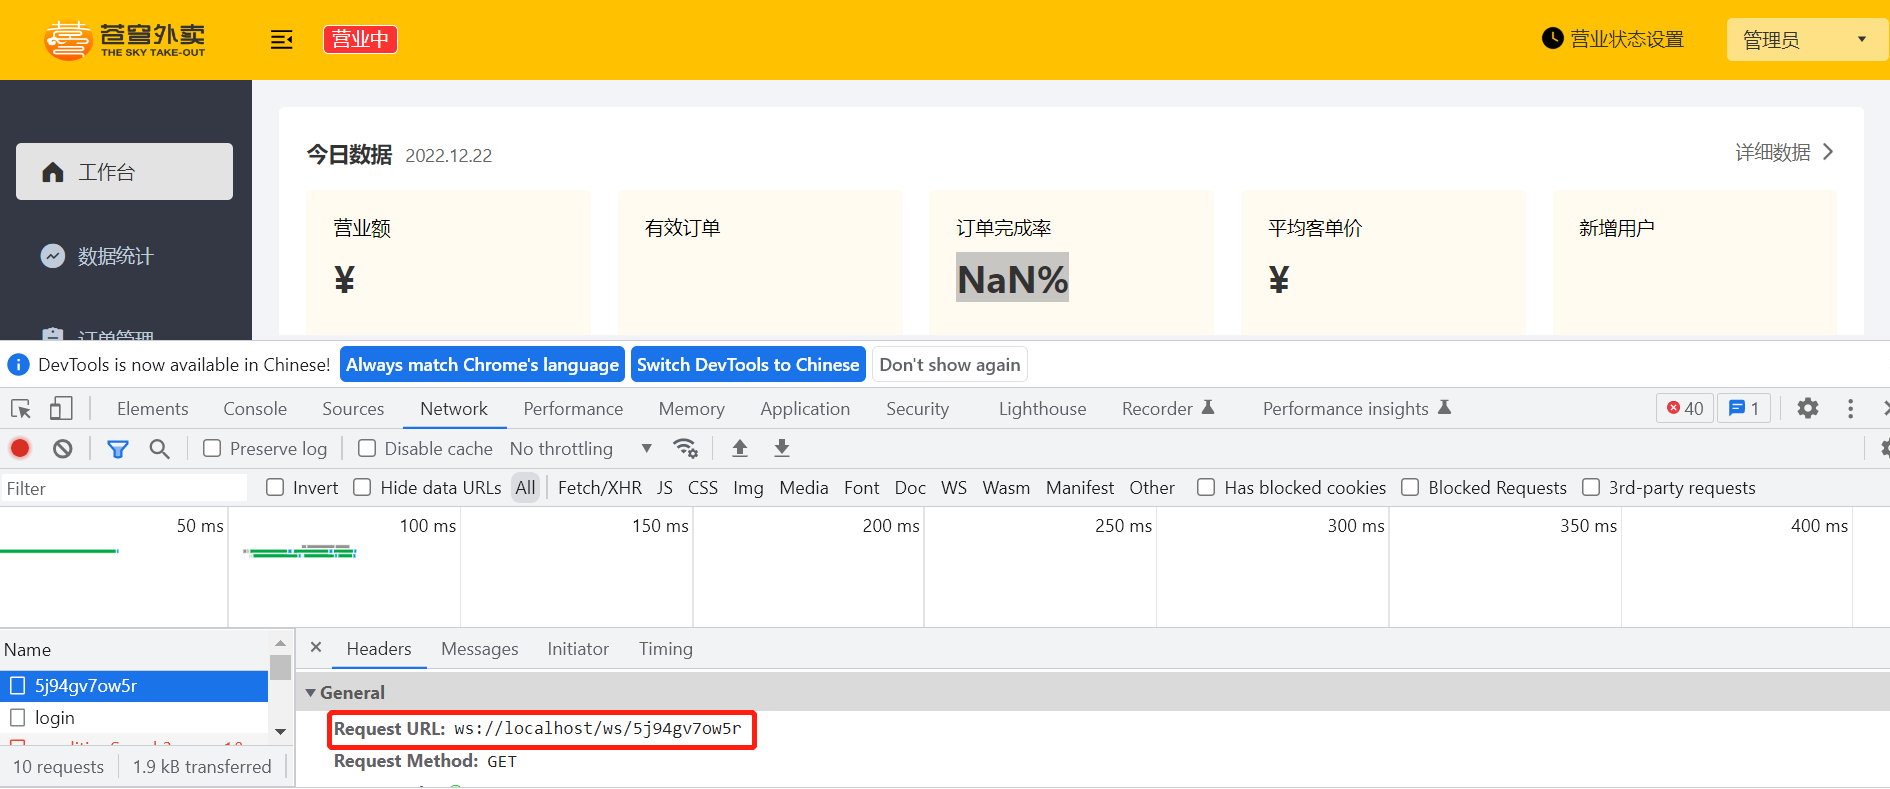 

查看控制台日志

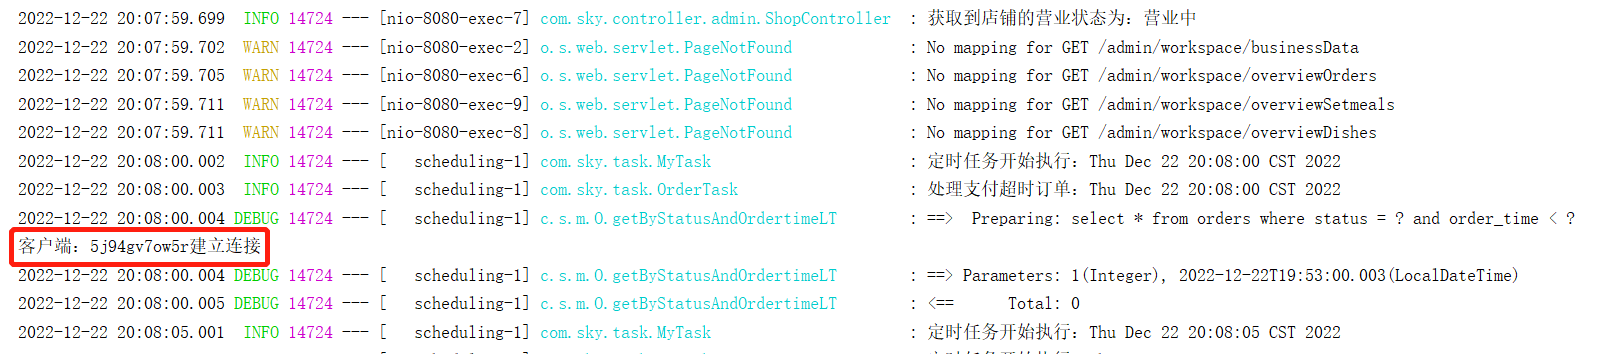 


**2). 用户进行催单**

用户可在订单列表或者订单详情，进行催单

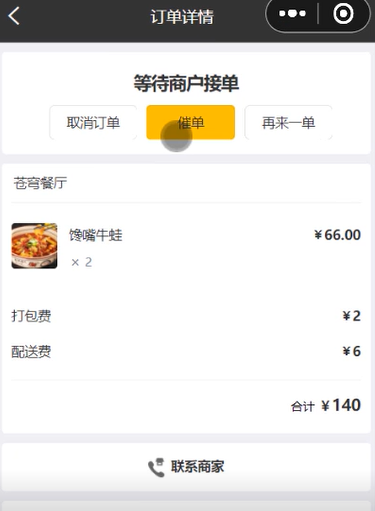 


**3). 查看催单提醒**

既有催单弹窗，同时语音播报

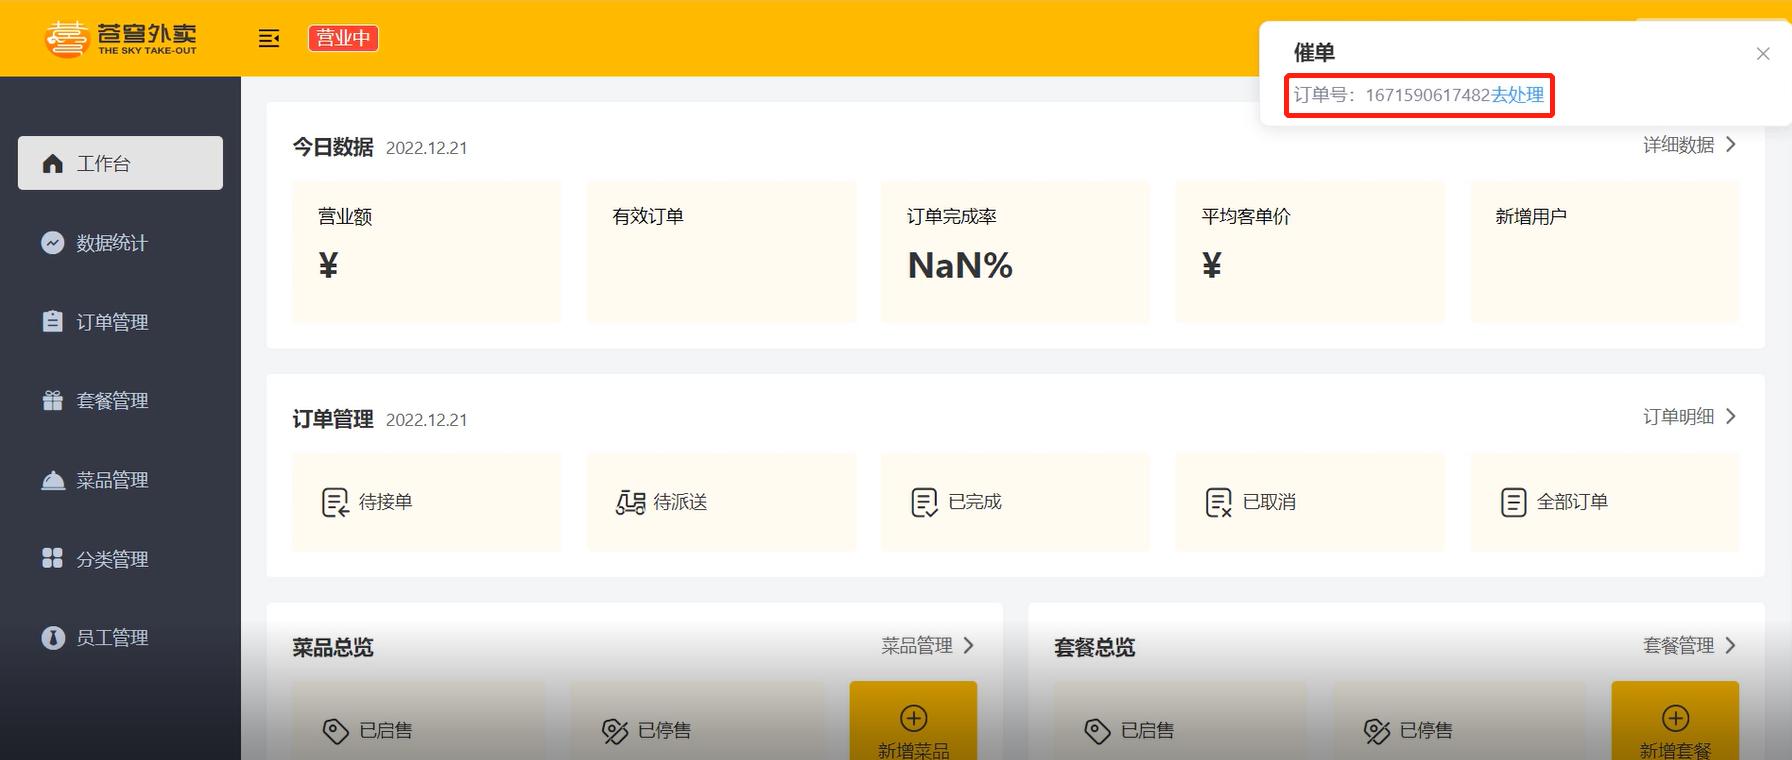


### 催单验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 当前用户的可催单订单 | 记录请求并推送 type=2 |
| 其他用户订单或猜测id | 拒绝，不推送 |
| 待付款、已取消、已完成订单 | 按业务规则拒绝 |
| 短时间连续点击 | 命中冷却或幂等规则，不洪泛 |
| 管理端在线/断线 | 在线收到消息，断线可从订单列表补看 |
| 订单号与订单id | 消息中的id能定位订单，订单号不泄露无关资料 |

联调时分别观察HTTP响应、服务端日志、WebSocket帧和订单状态。浏览器看到弹窗不代表授权和频率限制已经正确。


### 5.4 代码提交

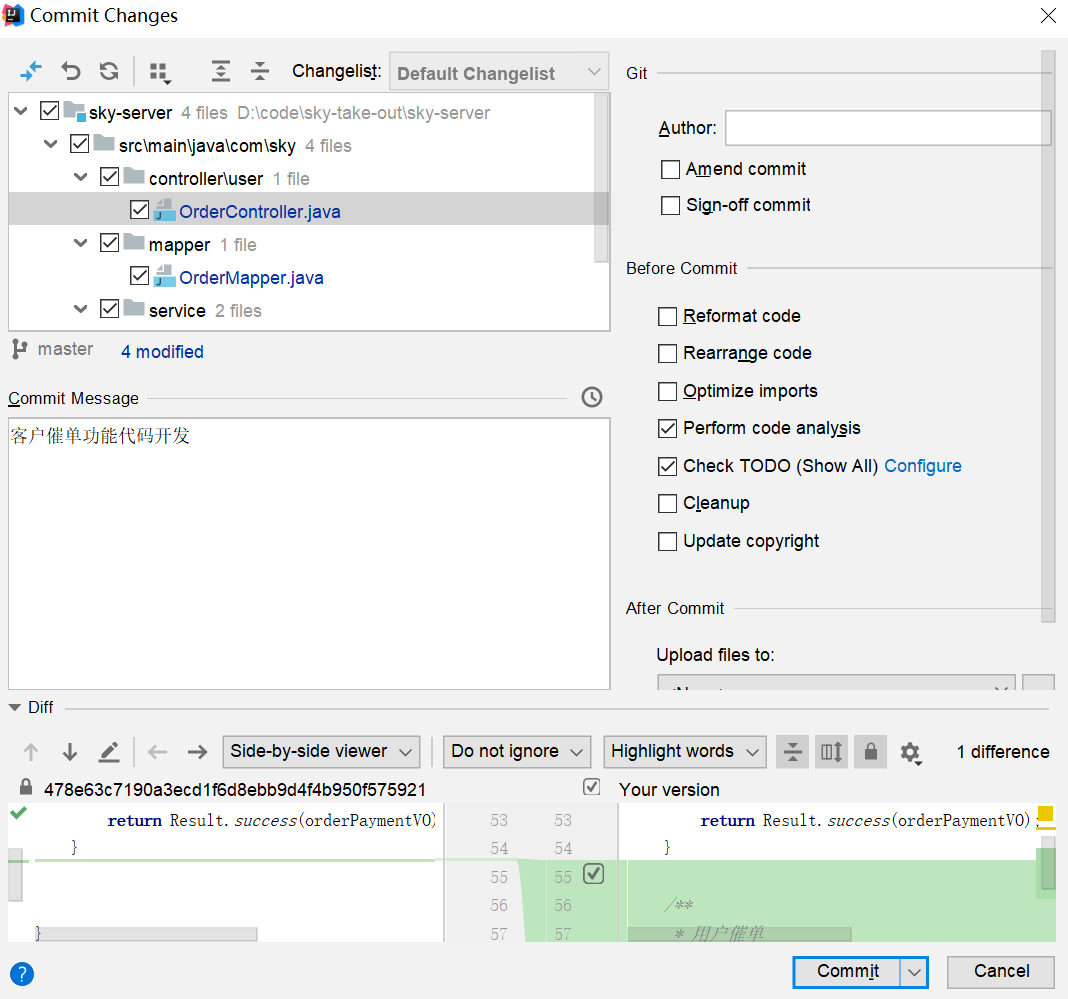 

后续步骤和其它功能代码提交一致，不再赘述。


### 提交前检查（补充）

提交催单功能前，检查订单归属、可催单状态、冷却时间、WebSocket断线兜底和日志脱敏；不要把用户提交的订单id直接交给无条件的 `getById` 查询。


## 复习速查与本章验收（补充）

| 知识点 | 核心记忆 |
| --- | --- |
| Spring Task | 进程内定时调度；多实例要锁或幂等 |
| cron | Spring常用六字段，确认时区与执行频率 |
| 自动取消 | 只处理待付款且未支付，条件更新防止覆盖支付 |
| 自动完成 | 只处理派送中，完成阈值按业务时间字段定义 |
| WebSocket | 长连接、双向通信；连接断开可重连，消息可补偿 |
| 会话容器 | 并发Map、广播快照、失败清理和超时 |
| 来单提醒 | 首次支付状态迁移后发送 type=1，重复通知不重复播报 |
| 客户催单 | 校验当前用户、订单状态和频率，发送 type=2 |
| 事务与推送 | 本地状态先提交，消息用提交后事件或outbox补偿 |

### 跟练验收清单

- [ ] 启动类开启 `@EnableScheduling`，任务类被 Spring 扫描。
- [ ] 支付超时和派送完成任务使用正确状态、时间字段与时区。
- [ ] 状态更新带前置条件，重复执行不会覆盖支付、接单或完成结果。
- [ ] 任务可观测，失败订单可定位，批量扫描有索引和分页策略。
- [ ] WebSocket连接生命周期完整，广播并发安全，失效连接能清理。
- [ ] 来单提醒只在首次可信支付成功后发送，断线可从订单列表补偿。
- [ ] 催单校验订单归属、状态与冷却时间，不可猜id越权。
- [ ] 推送消息字段稳定，日志不打印敏感订单资料。

### 自测问题

1. 为什么 `@Scheduled` 在多实例部署时可能执行多次？
2. `0 * * * * ?` 和 `0 0 1 * * ?` 分别何时触发？
3. 支付成功与自动取消同时发生时，数据库条件更新怎样避免覆盖？
4. 为什么自动完成不能只按下单时间硬编码60分钟？
5. WebSocket和HTTP分别适合哪些场景？
6. `HashMap<String, Session>` 在连接并发变化时有什么问题？
7. 为什么来单提醒要在事务提交后发送？
8. 重复支付通知如何避免重复语音播报？
9. 原催单接口按id查询会造成什么越权？
10. 管理端断线时，如何保证订单不会因为没收到推送而丢失？

本章把“定时改变状态”和“实时通知用户”连接起来，但订单数据仍以数据库状态和受保护查询为准；WebSocket消息只是及时提示。
